In [1]:
# CELL 1 — imports and display configuration
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)

print("Imports ready")
print("Python/pandas/numpy:", pd.__version__, np.__version__)


Imports ready
Python/pandas/numpy: 3.1.1 2.4.6


In [2]:
# CELL 2 — locate workstream and define paths
cwd = Path.cwd().resolve()
search_paths = [cwd, *cwd.parents]

WORKSTREAM_ROOT = next(
    (p for p in search_paths if p.name.lower() == "ml-workstream-nasa"),
    None
)

if WORKSTREAM_ROOT is None:
    PROJECT_ROOT = next(
        (p for p in search_paths if (p / "ml-workstream-nasa").is_dir()),
        None
    )
    if PROJECT_ROOT is not None:
        WORKSTREAM_ROOT = PROJECT_ROOT / "ml-workstream-nasa"

if WORKSTREAM_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ml-workstream-nasa. Open this notebook from "
        "inside the workstream or one of its subfolders."
    )

RAW_DIR = WORKSTREAM_ROOT / "data" / "raw" / "OSD-575"
INTERIM_DIR = WORKSTREAM_ROOT / "data" / "interim"
PROCESSED_DIR = WORKSTREAM_ROOT / "data" / "processed"
REPORTS_DIR = WORKSTREAM_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

for folder in [INTERIM_DIR, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not RAW_DIR.is_dir():
    raise FileNotFoundError(f"Raw OSD-575 folder not found: {RAW_DIR}")

print("Workstream:", WORKSTREAM_ROOT)
print("Raw data:", RAW_DIR)
print("Reports:", REPORTS_DIR)


Workstream: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa
Raw data: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\data\raw\OSD-575
Reports: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports


In [3]:
# CELL 3 — inventory files and select assay-result files
all_files = sorted(p for p in RAW_DIR.rglob("*") if p.is_file())
if not all_files:
    raise FileNotFoundError(f"No files found under {RAW_DIR}")

SUPPORTED_TABLE_SUFFIXES = {".csv", ".tsv", ".txt", ".xlsx", ".xlsm", ".xls"}
ISA_PREFIXES = ("a_", "i_", "s_")

inventory_rows = []
assay_paths = []

for path in all_files:
    suffix = path.suffix.lower()
    is_isa = path.name.lower().startswith(ISA_PREFIXES)
    is_table = suffix in SUPPORTED_TABLE_SUFFIXES
    # ISA metadata documents are kept as metadata, not assay measurements.
    # The assay result exports in this download use LSD-/assay-style names.
    is_result_candidate = is_table and not is_isa and (
        path.name.lower().startswith("lsd")
        or any(token in path.name.lower() for token in ["panel", "metabolic", "immuno", "cardio", "eve", "alamar"])
    )
    if is_result_candidate:
        assay_paths.append(path)

    inventory_rows.append({
        "file_name": path.name,
        "relative_path": str(path.relative_to(RAW_DIR)),
        "extension": suffix or "[no extension]",
        "size_bytes": path.stat().st_size,
        "is_isa_metadata": is_isa,
        "is_assay_result_candidate": is_result_candidate,
    })

file_inventory = pd.DataFrame(inventory_rows)
display(file_inventory)
file_inventory.to_csv(TABLES_DIR / "osd575_eda_file_inventory.csv", index=False)

print(f"\nFound {len(all_files)} files; selected {len(assay_paths)} assay-result candidates.")
if not assay_paths:
    raise RuntimeError(
        "No assay-result files were selected. Check actual file extensions and names "
        "in osd575_eda_file_inventory.csv, then update the selection rule if needed."
    )


,file_name,relative_path,extension,size_bytes,is_isa_metadata,is_assay_result_candidate
0,a_OSD-575_analytical-chemistry_comprehensive-m...,a_OSD-575_analytical-chemistry_comprehensive-m...,.txt,7973,True,False
1,a_OSD-575_immunoassay_multiplex_Alamar Bioscie...,a_OSD-575_immunoassay_multiplex_Alamar Bioscie...,.txt,10917,True,False
2,a_OSD-575_immunoassay_multiplex_Eve Technologi...,a_OSD-575_immunoassay_multiplex_Eve Technologi...,.txt,11665,True,False
3,a_OSD-575_immunoassay_multiplex_Eve Technologi...,a_OSD-575_immunoassay_multiplex_Eve Technologi...,.txt,13037,True,False
4,i_Investigation.txt,i_Investigation.txt,.txt,13753,True,False
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,.csv,25275,False,True
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,.csv,8506,False,True
7,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,.csv,15241,False,True
8,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBM...,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBM...,.xlsx,322799,False,True
9,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRAN...,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRAN...,.csv,141783,False,True



Found 14 files; selected 8 assay-result candidates.


In [4]:
# CELL 4 — robust readers for CSV/TSV/TXT and Excel workbooks
MAX_FILE_SIZE_MB = 100
assay_tables = {}
load_log = []


def read_delimited(path):
    """Read delimited text while preserving source column names and identifiers."""
    errors = []
    for encoding in ["utf-8-sig", "utf-8", "cp1252", "latin-1"]:
        try:
            # sep=None lets the Python engine infer comma/tab/semicolon in most exports.
            frame = pd.read_csv(path, encoding=encoding, sep=None, engine="python")
            if frame.shape[1] == 1:
                # Retry common delimiters if automatic inference produced one column.
                for sep in [",", "\t", ";"]:
                    retry = pd.read_csv(path, encoding=encoding, sep=sep)
                    if retry.shape[1] > 1:
                        frame = retry
                        break
            return frame
        except Exception as exc:
            errors.append(f"{encoding}: {type(exc).__name__}: {exc}")
    raise RuntimeError("; ".join(errors))


def load_assay_file(path):
    suffix = path.suffix.lower()
    if suffix in {".csv", ".tsv", ".txt"}:
        return {path.stem: read_delimited(path)}
    if suffix in {".xlsx", ".xlsm"}:
        # Every sheet is kept separately; workbook sheets can have different layouts.
        return {f"{path.stem}__{sheet}": frame
                for sheet, frame in pd.read_excel(path, sheet_name=None).items()}
    if suffix == ".xls":
        return {path.stem: pd.read_excel(path)}
    return {}

start_load = time.perf_counter()
for idx, path in enumerate(assay_paths, start=1):
    size_mb = path.stat().st_size / (1024 ** 2)
    if size_mb > MAX_FILE_SIZE_MB:
        load_log.append({"file": path.name, "status": "skipped_size_limit", "detail": f"{size_mb:.1f} MB"})
        print(f"[{idx}/{len(assay_paths)}] Skipped (size limit): {path.name}")
        continue
    try:
        loaded = load_assay_file(path)
        for table_key, frame in loaded.items():
            # Remove completely unnamed columns that Excel exports sometimes create.
            frame = frame.loc[:, ~frame.columns.astype(str).str.match(r"^Unnamed")].copy()
            assay_tables[table_key] = frame
            load_log.append({"file": path.name, "table": table_key, "status": "loaded", "rows": len(frame), "columns": len(frame.columns), "detail": ""})
            print(f"[{idx}/{len(assay_paths)}] Loaded {table_key}: {frame.shape}")
    except Exception as exc:
        load_log.append({"file": path.name, "status": "error", "detail": f"{type(exc).__name__}: {exc}"})
        print(f"[{idx}/{len(assay_paths)}] ERROR {path.name}: {exc}")

load_log_df = pd.DataFrame(load_log)
load_log_df.to_csv(TABLES_DIR / "osd575_eda_load_log.csv", index=False)
print(f"\nLoaded {len(assay_tables)} tables in {time.perf_counter() - start_load:.2f} seconds.")
if not assay_tables:
    raise RuntimeError("No assay tables loaded. Review osd575_eda_load_log.csv.")


[1/8] Loaded LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED: (531, 9)
[2/8] Loaded LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED: (28, 58)
[3/8] Loaded LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED: (252, 8)
[4/8] ERROR LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx: `Import openpyxl` failed.  Use pip, conda, or your preferred package management tool to install the openpyxl package.
[5/8] Loaded LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED: (27, 407)
[6/8] Loaded LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED: (1988, 8)
[7/8] Loaded LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED: (28, 19)
[8/8] Loaded LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED: (28, 143)

Loaded 7 tables in 0.04 seconds.


In [5]:
# CELL 5 — print each table's schema and preview
schema_rows = []
for name, frame in assay_tables.items():
    print("\n" + "=" * 90)
    print(name, "| shape:", frame.shape)
    print("Columns:")
    for col in frame.columns:
        print(f"  - {col!s} ({frame[col].dtype})")
        schema_rows.append({"table": name, "column": str(col), "dtype": str(frame[col].dtype), "non_null": int(frame[col].notna().sum()), "unique_non_null": int(frame[col].nunique(dropna=True))})
    display(frame.head(5))

schema_df = pd.DataFrame(schema_rows)
schema_df.to_csv(TABLES_DIR / "osd575_eda_table_schema.csv", index=False)



LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED | shape: (531, 9)
Columns:
  - ANALYTE (str)
  - VALUE (float64)
  - RANGE_MIN (float64)
  - RANGE_MAX (float64)
  - UNITS (str)
  - TEST_TYPE (str)
  - SUBJECT_ID (str)
  - SEX (str)
  - timepoint (str)


,ANALYTE,VALUE,RANGE_MIN,RANGE_MAX,UNITS,TEST_TYPE,SUBJECT_ID,SEX,timepoint
0,GLUCOSE,83.00,65.0,99.00,mg/dL,CMP,C001,M,L-92
1,UREA NITROGEN (BUN),25.00,7.0,25.00,mg/dL,CMP,C001,M,L-92
2,CREATININE,1.24,0.6,1.35,mg/dL,CMP,C001,M,L-92
3,eGFR NON-AFR. AMERICAN,73.00,60.0,NaN,mL/min/1.73m2,CMP,C001,M,L-92
4,eGFR AFRICAN AMERICAN,85.00,60.0,NaN,mL/min/1.73m2,CMP,C001,M,L-92



LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED | shape: (28, 58)
Columns:
  - Sample Name (str)
  - albumin_value_gram_per_deciliter (float64)
  - albumin_range_min_gram_per_deciliter (float64)
  - albumin_range_max_gram_per_deciliter (float64)
  - albumin_to_globulin_ratio_value (float64)
  - albumin_to_globulin_ratio_range_min (int64)
  - albumin_to_globulin_ratio_range_max (float64)
  - alkaline_phosphatase_value_units_per_liter (int64)
  - alkaline_phosphatase_range_min_units_per_liter (int64)
  - alkaline_phosphatase_range_max_units_per_liter (int64)
  - alt_value_units_per_liter (int64)
  - alt_range_min_units_per_liter (int64)
  - alt_max_units_per_liter (int64)
  - ast_value_units_per_liter (int64)
  - ast_range_min_units_per_liter (int64)
  - ast_max_units_per_liter (int64)
  - total_bilirubin_value_milligram_per_deciliter (float64)
  - total_bilirubin_range_min_milligram_per_deciliter (float64)
  - total_bilirubin_range_max_milligram_per_deciliter (float64)
  - bun_to_

,Sample Name,albumin_value_gram_per_deciliter,albumin_range_min_gram_per_deciliter,albumin_range_max_gram_per_deciliter,albumin_to_globulin_ratio_value,albumin_to_globulin_ratio_range_min,albumin_to_globulin_ratio_range_max,alkaline_phosphatase_value_units_per_liter,alkaline_phosphatase_range_min_units_per_liter,alkaline_phosphatase_range_max_units_per_liter,alt_value_units_per_liter,alt_range_min_units_per_liter,alt_max_units_per_liter,ast_value_units_per_liter,ast_range_min_units_per_liter,ast_max_units_per_liter,total_bilirubin_value_milligram_per_deciliter,total_bilirubin_range_min_milligram_per_deciliter,total_bilirubin_range_max_milligram_per_deciliter,bun_to_creatinine_ratio_value,bun_to_creatinine_ratio_range_min,bun_to_creatinine_ratio_range_max,calcium_value_milligram_per_deciliter,calcium_range_min_milligram_per_deciliter,calcium_range_max_milligram_per_deciliter,carbon_dioxide_value_millimol_per_liter,carbon_dioxide_range_min_millimol_per_liter,carbon_dioxide_range_max_millimol_per_liter,chloride_value_millimol_per_liter,chloride_range_min_millimol_per_liter,chloride_range_max_millimol_per_liter,creatinine_value_milligram_per_deciliter,creatinine_range_min_milligram_per_deciliter,creatinine_range_max_milligram_per_deciliter,egfr_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,globulin_value_gram_per_deciliter,globulin_range_min_gram_per_deciliter,globulin_range_max_gram_per_deciliter,glucose_value_milligram_per_deciliter,glucose_range_min_milligram_per_deciliter,glucose_range_max_milligram_per_deciliter,potassium_value_millimol_per_liter,potassium_range_min_millimol_per_liter,potassium_range_max_millimol_per_liter,total_protein_value_gram_per_deciliter,total_protein_range_min_gram_per_deciliter,total_protein_range_max_gram_per_deciliter,sodium_value_millimol_per_liter,sodium_range_min_millimol_per_liter,sodium_range_max_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter,urea_nitrogen_bun_range_min_milligram_per_deciliter,urea_nitrogen_bun_range_max_milligram_per_deciliter
0,C001_serum_L-3,4.9,3.6,5.1,2.0,1,2.5,45,36,130,13,9,46,15,10,40,1.0,0.2,1.2,15.0,6.0,22.0,9.6,8.6,10.3,26,20,32,102,98,110,1.37,0.6,1.35,75,60,NaN,65,60,NaN,2.5,1.9,3.7,69,65,99,3.9,3.5,5.3,7.4,6.1,8.1,142,135,146,20,7,25
1,C001_serum_L-44,5.0,3.6,5.1,1.9,1,2.5,46,36,130,16,9,46,18,10,40,0.9,0.2,1.2,NaN,6.0,22.0,10.0,8.6,10.3,26,20,32,101,98,110,1.10,0.6,1.35,98,60,NaN,85,60,NaN,2.7,1.9,3.7,80,65,99,4.2,3.5,5.3,7.7,6.1,8.1,139,135,146,19,7,25
2,C001_serum_L-92,5.0,3.6,5.1,2.2,1,2.5,51,36,130,15,9,46,15,10,40,0.7,0.2,1.2,NaN,6.0,22.0,9.7,8.6,10.3,23,20,32,104,98,110,1.24,0.6,1.35,85,60,NaN,73,60,NaN,2.3,1.9,3.7,83,65,99,4.6,3.5,5.3,7.3,6.1,8.1,141,135,146,25,7,25
3,C001_serum_R+1,4.9,3.6,5.1,1.9,1,2.5,52,36,130,9,9,46,16,10,40,1.2,0.2,1.2,NaN,6.0,22.0,9.7,8.6,10.3,24,20,32,102,98,110,1.12,0.6,1.35,96,60,NaN,83,60,NaN,2.6,1.9,3.7,90,65,99,4.4,3.5,5.3,7.5,6.1,8.1,138,135,146,18,7,25
4,C001_serum_R+194,4.6,3.6,5.1,1.9,1,2.5,50,36,130,15,9,46,12,10,40,0.8,0.2,1.2,22.0,6.0,22.0,9.4,8.6,10.3,23,20,32,102,98,110,1.29,0.6,1.35,80,60,NaN,69,60,NaN,2.4,1.9,3.7,87,65,99,4.3,3.5,5.3,7.0,6.1,8.1,137,135,146,28,7,25



LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED | shape: (252, 8)
Columns:
  - Analyte (str)
  - Concentration (float64)
  - Timepoint (str)
  - ID (str)
  - Unit (str)
  - Timepoint2 (str)
  - Type (str)
  - Percent (float64)


,Analyte,Concentration,Timepoint,ID,Unit,Timepoint2,Type,Percent
0,a-2 Macroglobulin,903742.69,L-92,C001,ng/ml,Preflight,HDCVD9,61.947276
1,a-2 Macroglobulin,2036900.00,L-92,C002,ng/ml,Preflight,HDCVD9,139.619837
2,a-2 Macroglobulin,3030400.00,L-92,C003,ng/ml,Preflight,HDCVD9,207.719551
3,a-2 Macroglobulin,1354300.00,L-92,C004,ng/ml,Preflight,HDCVD9,92.830843
4,a-2 Macroglobulin,657943.56,L-44,C001,ng/ml,Preflight,HDCVD9,45.098911


... (4 outputs left out)


LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED | shape: (28, 19)
Columns:
  - Sample Name (str)
  - a2_macroglobulin_concentration_nanogram_per_milliliter (float64)
  - a2_macroglobulin_percent (float64)
  - agp_concentration_nanogram_per_milliliter (float64)
  - agp_percent (float64)
  - crp_concentration_picogram_per_milliliter (int64)
  - crp_percent (float64)
  - fetuin_a36_concentration_nanogram_per_milliliter (float64)
  - fetuin_a36_percent (float64)
  - fibrinogen_concentration_nanogram_per_milliliter (float64)
  - fibrinogen_percent (float64)
  - haptoglobin_concentration_nanogram_per_milliliter (float64)
  - haptoglobin_percent (float64)
  - l_selectin_concentration_picogram_per_milliliter (float64)
  - l_selectin_percent (float64)
  - pf4_concentration_nanogram_per_milliliter (float64)
  - pf4_percent (float64)
  - sap_concentration_picogram_per_milliliter (int64)
  - sap_percent (float64)


,Sample Name,a2_macroglobulin_concentration_nanogram_per_milliliter,a2_macroglobulin_percent,agp_concentration_nanogram_per_milliliter,agp_percent,crp_concentration_picogram_per_milliliter,crp_percent,fetuin_a36_concentration_nanogram_per_milliliter,fetuin_a36_percent,fibrinogen_concentration_nanogram_per_milliliter,fibrinogen_percent,haptoglobin_concentration_nanogram_per_milliliter,haptoglobin_percent,l_selectin_concentration_picogram_per_milliliter,l_selectin_percent,pf4_concentration_nanogram_per_milliliter,pf4_percent,sap_concentration_picogram_per_milliliter,sap_percent
0,C001_serum_L-3,1002300.00,68.702912,1214100.0,56.505028,5131700,28.972195,155302.07,63.401726,2780.38,65.861344,1305900.00,22.434959,561452.93,57.944587,8602.35,74.659519,6057300,66.132482
1,C001_serum_L-44,657943.56,45.098911,1745700.0,81.246049,2191000,12.369795,194978.74,79.599639,5707.32,135.194386,122441.48,2.103507,675114.37,69.674983,3903.78,33.880781,5428000,59.261901
2,C001_serum_L-92,903742.69,61.947276,1048700.0,48.807201,18385000,103.796754,144424.41,58.960946,3208.77,76.009001,1049100.00,18.023214,515957.20,53.249214,6973.32,60.521220,4760000,51.968801
3,C001_serum_R+1,1048700.00,71.883412,1034400.0,48.141670,10637600,60.057022,163848.05,66.890603,2604.70,61.699855,853104.40,14.656070,596429.89,61.554374,8143.69,70.678823,6183500,67.510311
4,C001_serum_R+194,1651200.00,113.181931,2595800.0,120.810273,15415000,87.028934,273640.25,111.713026,4587.13,108.659445,55113000.00,946.824327,762532.23,78.696918,11371.31,98.691233,7739400,84.497339



LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED | shape: (28, 143)
Columns:
  - Sample Name (str)
  - 6ckine_concentration_picogram_per_milliliter (float64)
  - 6ckine_percent (float64)
  - bca_1_concentration_picogram_per_milliliter (float64)
  - bca_1_percent (float64)
  - ctack_concentration_picogram_per_milliliter (float64)
  - ctack_percent (float64)
  - egf_concentration_picogram_per_milliliter (float64)
  - egf_percent (float64)
  - ena_78_concentration_picogram_per_milliliter (float64)
  - ena_78_percent (float64)
  - eotaxin_concentration_picogram_per_milliliter (float64)
  - eotaxin_percent (float64)
  - eotaxin_2_concentration_picogram_per_milliliter (float64)
  - eotaxin_2_percent (float64)
  - eotaxin_3_concentration_picogram_per_milliliter (float64)
  - eotaxin_3_percent (float64)
  - fgf_2_concentration_picogram_per_milliliter (float64)
  - fgf_2_percent (float64)
  - flt_3l_concentration_picogram_per_milliliter (float64)
  - flt_3l_percent (float64)
  - fractalkine_

,Sample Name,6ckine_concentration_picogram_per_milliliter,6ckine_percent,bca_1_concentration_picogram_per_milliliter,bca_1_percent,ctack_concentration_picogram_per_milliliter,ctack_percent,egf_concentration_picogram_per_milliliter,egf_percent,ena_78_concentration_picogram_per_milliliter,ena_78_percent,eotaxin_concentration_picogram_per_milliliter,eotaxin_percent,eotaxin_2_concentration_picogram_per_milliliter,eotaxin_2_percent,eotaxin_3_concentration_picogram_per_milliliter,eotaxin_3_percent,fgf_2_concentration_picogram_per_milliliter,fgf_2_percent,flt_3l_concentration_picogram_per_milliliter,flt_3l_percent,fractalkine_concentration_picogram_per_milliliter,fractalkine_percent,g_csf_concentration_picogram_per_milliliter,g_csf_percent,gm_csf_concentration_picogram_per_milliliter,gm_csf_percent,groα_concentration_picogram_per_milliliter,groα_percent,i_309_concentration_picogram_per_milliliter,i_309_percent,ifn_α2_concentration_picogram_per_milliliter,ifn_α2_percent,ifnγ_concentration_picogram_per_milliliter,ifnγ_percent,il_10_concentration_picogram_per_milliliter,il_10_percent,il_12p40_concentration_picogram_per_milliliter,il_12p40_percent,il_12p70_concentration_picogram_per_milliliter,...,mcp_4_concentration_picogram_per_milliliter,mcp_4_percent,mdc_concentration_picogram_per_milliliter,mdc_percent,mig_per_cxcl9_concentration_picogram_per_milliliter,mig_per_cxcl9_percent,mip_1α_concentration_picogram_per_milliliter,mip_1α_percent,mip_1β_concentration_picogram_per_milliliter,mip_1β_percent,mip_1δ_concentration_picogram_per_milliliter,mip_1δ_percent,pdgf_aa_concentration_picogram_per_milliliter,pdgf_aa_percent,pdgf_ab_per_bb_concentration_picogram_per_milliliter,pdgf_ab_per_bb_percent,rantes_concentration_picogram_per_milliliter,rantes_percent,scd40l_concentration_picogram_per_milliliter,scd40l_percent,scf_concentration_picogram_per_milliliter,scf_percent,sdf_1α_plus_β_concentration_picogram_per_milliliter,sdf_1α_plus_β_percent,tarc_concentration_picogram_per_milliliter,tarc_percent,tgfα_concentration_picogram_per_milliliter,tgfα_percent,tnfα_concentration_picogram_per_milliliter,tnfα_percent,tnfβ_concentration_picogram_per_milliliter,tnfβ_percent,tpo_concentration_picogram_per_milliliter,tpo_percent,trail_concentration_picogram_per_milliliter,trail_percent,tslp_concentration_picogram_per_milliliter,tslp_percent,vegf_a_concentration_picogram_per_milliliter,vegf_a_percent
0,C001_serum_L-3,909.52,87.230109,72.49,144.748403,1439.51,134.778429,916.85,184.263679,1526.33,155.164378,50.62,52.487233,1508.62,198.493273,26.62,56.432180,173.13,91.818957,23.47,130.642917,300.53,47.184087,59.56,89.310974,65.09,12.792888,35.62,86.267861,1.40,66.561014,201.71,167.467154,3.05,10.331687,7.07,75.554368,144.21,91.927670,15.38,...,94.22,75.301201,2801.86,174.616320,3063.44,133.844468,79.25,93.595914,72.43,86.306675,5087.16,121.681918,1235.59,13.659555,251163.70,197.814489,2602.42,73.874951,24009.05,162.435025,51.62,76.496740,6656.76,90.154302,137.87,121.440158,32.88,127.660401,68.71,38.307896,14.80,13.271261,993.21,106.186298,109.03,167.270961,9.52,74.234843,943.22,133.873307
1,C001_serum_L-44,844.40,80.984590,49.83,99.500799,1134.00,106.174142,438.11,88.049038,994.81,101.130866,27.05,28.047801,773.57,101.780727,34.32,72.755538,183.18,97.148944,13.75,76.537712,148.59,23.329064,68.27,102.371729,82.09,16.134094,19.88,48.147251,1.81,86.053883,78.61,65.264949,6.05,20.494001,3.44,36.761956,96.65,61.610216,6.47,...,122.54,97.934718,754.68,47.032844,1839.35,80.362868,93.42,110.330981,66.41,79.133319,4239.07,101.396097,469.71,5.192685,32107.23,25.287393,406.74,11.546137,10055.91,68.034012,58.10,86.099585,5651.45,76.539117,122.41,107.822513,20.08,77.962921,60.14,33.529863,10.68,9.576829,744.11,79.554461,94.08,144.335063,4.48,34.934044,465.63,66.087899
2,C001_serum_L-92,862.46,82.716686,68.35,136.481629,1054.15,98.697947,639.33,128.489172,687.22,69.861736,56.39,58.470073,1443.33,189.902888,23.29,49.372858,173.13,91.818957,24.85,138.324520,293.91,46.144728,61.9

In [6]:
# CELL 6 — infer table provenance and assay family from filenames

def classify_table(name):
    text = name.lower()
    if "cmp" in text or "comprehensive_metabolic" in text:
        family = "comprehensive_metabolic_panel"
    elif "hdcvd9" in text or "cardiovascular" in text or "cvd" in text:
        family = "cardiovascular_multiplex"
    elif "alamar" in text:
        family = "immune_alamar_multiplex"
    elif "hd71" in text or "evepanel" in text or "immune" in text:
        family = "immune_eve_multiplex"
    else:
        family = "unknown_assay_family"

    if "transformed" in text:
        version = "TRANSFORMED"
    elif "submitted" in text or "upload" in text:
        version = "SUBMITTED"
    else:
        version = "unspecified"
    return family, version

provenance_rows = []
for name, frame in assay_tables.items():
    family, version = classify_table(name)
    provenance_rows.append({"table": name, "assay_family": family, "file_version": version, "rows": len(frame), "columns": len(frame.columns)})

provenance_df = pd.DataFrame(provenance_rows)
display(provenance_df.sort_values(["assay_family", "file_version", "table"]))
provenance_df.to_csv(TABLES_DIR / "osd575_assay_provenance.csv", index=False)


,table,assay_family,file_version,rows,columns
2,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,cardiovascular_multiplex,SUBMITTED,252,8
5,LSDS-8_Multiplex_serum_cardiovascular_EvePanel...,cardiovascular_multiplex,TRANSFORMED,28,19
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,comprehensive_metabolic_panel,SUBMITTED,531,9
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,comprehensive_metabolic_panel,TRANSFORMED,28,58
3,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRAN...,immune_alamar_multiplex,TRANSFORMED,27,407
4,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED,immune_eve_multiplex,SUBMITTED,1988,8
6,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,immune_eve_multiplex,TRANSFORMED,28,143


In [7]:
# CELL 7 — detect identifier, timepoint, analyte, unit and result columns
IDENTIFIER_RE = re.compile(r"(subject|participant|crew|astronaut|sample|specimen|biospecimen|subject.?id|sample.?id|factor.?value)", re.I)
TIME_RE = re.compile(r"(time.?point|time.?collected|collection.?time|visit|flight.?day|timepoint|factor.?value.*time|time)", re.I)
ANALYTE_RE = re.compile(r"(analyte|biomarker|protein|marker|test.?name|component|parameter|feature)", re.I)
UNIT_RE = re.compile(r"(unit|uom)", re.I)
VALUE_RE = re.compile(r"(value|result|concentration|measurement|intensity|signal|abundance|level)", re.I)

column_roles = []
for name, frame in assay_tables.items():
    for col in frame.columns:
        col_s = str(col)
        roles = []
        if IDENTIFIER_RE.search(col_s): roles.append("identifier_or_sample")
        if TIME_RE.search(col_s): roles.append("timepoint_candidate")
        if ANALYTE_RE.search(col_s): roles.append("analyte_candidate")
        if UNIT_RE.search(col_s): roles.append("unit_candidate")
        if VALUE_RE.search(col_s): roles.append("measurement_value_candidate")
        if pd.api.types.is_numeric_dtype(frame[col]): roles.append("numeric_dtype")
        column_roles.append({"table": name, "column": col_s, "roles": ";".join(roles) if roles else "unclassified"})

column_roles_df = pd.DataFrame(column_roles)
display(column_roles_df)
column_roles_df.to_csv(TABLES_DIR / "osd575_column_role_candidates.csv", index=False)


,table,column,roles
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,ANALYTE,analyte_candidate
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,measurement_value_candidate;numeric_dtype
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,RANGE_MIN,numeric_dtype
3,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,RANGE_MAX,numeric_dtype
4,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,UNITS,unit_candidate
...,...,...,...
647,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,trail_percent,numeric_dtype
648,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,tslp_concentration_picogram_per_milliliter,measurement_value_candidate;numeric_dtype
649,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,tslp_percent,numeric_dtype
650,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,vegf_a_concentration_picogram_per_milliliter,measurement_value_candidate;numeric_dtype


In [8]:
# CELL 8 — numeric measurement summaries and missingness
# In long-format multiplex data, never pool raw values across different analytes or units.
measurement_summary_rows = []
missingness_rows = []

for name, frame in assay_tables.items():
    analyte_cols = [c for c in frame.columns if ANALYTE_RE.search(str(c))]
    unit_cols = [c for c in frame.columns if UNIT_RE.search(str(c))]
    analyte_col = analyte_cols[0] if len(analyte_cols) == 1 else None
    unit_col = unit_cols[0] if len(unit_cols) == 1 else None

    for col in frame.columns:
        series = frame[col]
        missingness_rows.append({
            "table": name,
            "column": str(col),
            "missing_count": int(series.isna().sum()),
            "missing_percent": float(series.isna().mean() * 100) if len(series) else np.nan,
            "unique_non_null": int(series.nunique(dropna=True)),
        })

    numeric_cols = []
    for col in frame.columns:
        numeric = pd.to_numeric(frame[col], errors="coerce")
        original_nonmissing = int(frame[col].notna().sum())
        numeric_nonmissing = int(numeric.notna().sum())
        if original_nonmissing and numeric_nonmissing / original_nonmissing >= 0.80 and numeric.notna().any():
            numeric_cols.append(col)

    for col in numeric_cols:
        numeric = pd.to_numeric(frame[col], errors="coerce")
        if analyte_col is not None:
            grouping_cols = [analyte_col]
            if unit_col is not None and unit_col != analyte_col:
                grouping_cols.append(unit_col)
            grouped = frame.assign(_numeric_value=numeric).groupby(grouping_cols, dropna=False, sort=False)["_numeric_value"]
            for group_key, values in grouped:
                if not isinstance(group_key, tuple):
                    group_key = (group_key,)
                finite = values[np.isfinite(values)]
                measurement_summary_rows.append({
                    "table": name,
                    "measurement_column": str(col),
                    "analyte": str(group_key[0]),
                    "unit": str(group_key[1]) if len(group_key) > 1 else "",
                    "n_numeric": int(finite.size),
                    "n_missing_or_nonfinite": int(len(values) - finite.size),
                    "mean": float(finite.mean()) if finite.size else np.nan,
                    "std": float(finite.std()) if finite.size > 1 else np.nan,
                    "min": float(finite.min()) if finite.size else np.nan,
                    "median": float(finite.median()) if finite.size else np.nan,
                    "max": float(finite.max()) if finite.size else np.nan,
                })
        else:
            finite = numeric[np.isfinite(numeric)]
            measurement_summary_rows.append({
                "table": name,
                "measurement_column": str(col),
                "analyte": str(col),
                "unit": str(frame[unit_col].dropna().iloc[0]) if unit_col is not None and frame[unit_col].notna().any() else "",
                "n_numeric": int(finite.size),
                "n_missing_or_nonfinite": int(len(numeric) - finite.size),
                "mean": float(finite.mean()) if finite.size else np.nan,
                "std": float(finite.std()) if finite.size > 1 else np.nan,
                "min": float(finite.min()) if finite.size else np.nan,
                "median": float(finite.median()) if finite.size else np.nan,
                "max": float(finite.max()) if finite.size else np.nan,
            })

measurement_summary = pd.DataFrame(measurement_summary_rows)
missingness_summary = pd.DataFrame(missingness_rows)
display(measurement_summary)
measurement_summary.to_csv(TABLES_DIR / "osd575_numeric_measurement_summary.csv", index=False)
missingness_summary.to_csv(TABLES_DIR / "osd575_column_missingness.csv", index=False)


,table,measurement_column,analyte,unit,n_numeric,n_missing_or_nonfinite,mean,std,min,median,max
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,GLUCOSE,mg/dL,28,0,76.428571,16.226244,36.000000,80.000000,103.000000
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,UREA NITROGEN (BUN),mg/dL,28,0,20.357143,3.992718,14.000000,19.000000,28.000000
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,CREATININE,mg/dL,28,0,1.067500,0.143466,0.820000,1.080000,1.370000
3,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,eGFR NON-AFR. AMERICAN,mL/min/1.73m2,28,0,76.178571,7.727074,63.000000,77.000000,88.000000
4,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,VALUE,eGFR AFRICAN AMERICAN,mL/min/1.73m2,28,0,88.214286,8.945751,73.000000,89.000000,102.000000
...,...,...,...,...,...,...,...,...,...,...,...
833,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,trail_percent,trail_percent,,28,0,102.085015,48.910039,27.078166,102.636222,190.390959
834,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,tslp_concentration_picogram_per_milliliter,tslp_concentration_picogram_per_milliliter,,28,0,9.861071,9.192278,1.330000,6.595000,33.730000
835,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,tslp_percent,tslp_percent,,28,0,76.894442,71.679342,10.371044,51.426343,263.019040
836,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,vegf_a_concentration_picogram_per_milliliter,vegf_a_concentration_picogram_per_milliliter,,28,0,710.614286,262.850107,243.340000,660.300000,1281.810000


In [9]:
# CELL 9 — identify possible subject/timepoint categories from actual column values
# This is a discovery aid. It does not automatically assert that a column is a valid subject or visit label.
timepoint_token_re = re.compile(r"\b(?:L\s*[-+]\s*\d+|R\s*\+\s*\d+|pre.?flight|post.?flight|baseline|in.?flight)\b", re.I)
subject_token_re = re.compile(r"\bC00[1-4]\b", re.I)
category_rows = []

for name, frame in assay_tables.items():
    for col in frame.columns:
        s = frame[col]
        if pd.api.types.is_numeric_dtype(s):
            continue
        vals = s.dropna().astype(str).str.strip()
        if vals.empty:
            continue
        time_hits = sorted({v for v in vals.unique() if timepoint_token_re.search(v)})
        subject_hits = sorted({v for v in vals.unique() if subject_token_re.search(v)})
        if time_hits or subject_hits or TIME_RE.search(str(col)) or IDENTIFIER_RE.search(str(col)):
            category_rows.append({
                "table": name,
                "column": str(col),
                "n_unique": int(vals.nunique()),
                "timepoint_like_values": " | ".join(time_hits[:30]),
                "subject_like_values": " | ".join(subject_hits[:20]),
                "sample_values": " | ".join(vals.unique()[:12]),
            })

category_candidates = pd.DataFrame(category_rows)
display(category_candidates)
category_candidates.to_csv(TABLES_DIR / "osd575_subject_timepoint_candidates.csv", index=False)


,table,column,n_unique,timepoint_like_values,subject_like_values,sample_values
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,SUBJECT_ID,4,,C001 | C002 | C003 | C004,C001 | C002 | C004 | C003
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,7,L-3 | L-44 | L-92 | R+1 | R+194 | R+45 | R+82,,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,Sample Name,28,,,C001_serum_L-3 | C001_serum_L-44 | C001_serum_...
3,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,Timepoint,7,L-3 | L-44 | L-92 | R+1 | R+194 | R+45 | R+82,,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
4,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,ID,4,,C001 | C002 | C003 | C004,C001 | C002 | C003 | C004
5,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,Timepoint2,5,Preflight | R+1 | R+194 | R+45 | R+82,,Preflight | R+1 | R+45 | R+82 | R+194
6,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRAN...,Sample ID,27,,,C001_serum_L-92 | C002_serum_L-92 | C003_serum...
7,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED,Timepoint,7,L-3 | L-44 | L-92 | R+1 | R+194 | R+45 | R+82,,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
8,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED,ID,4,,C001 | C002 | C003 | C004,C001 | C002 | C003 | C004
9,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED,Timepoint2,5,Preflight | R+1 | R+194 | R+45 | R+82,,Preflight | R+1 | R+45 | R+82 | R+194


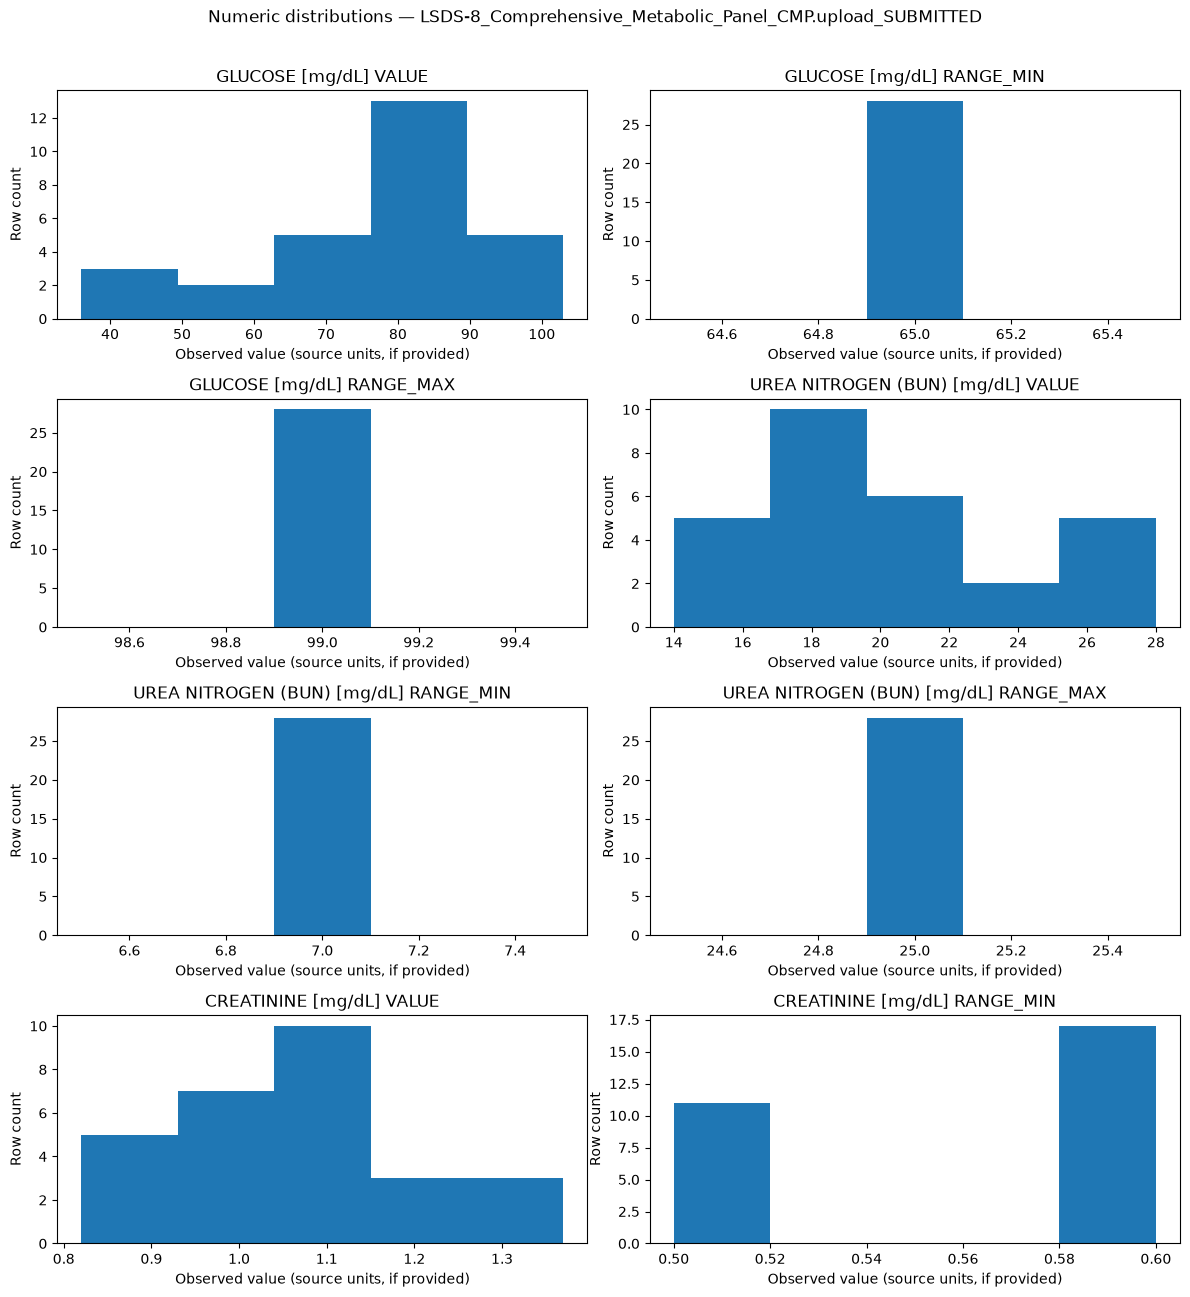

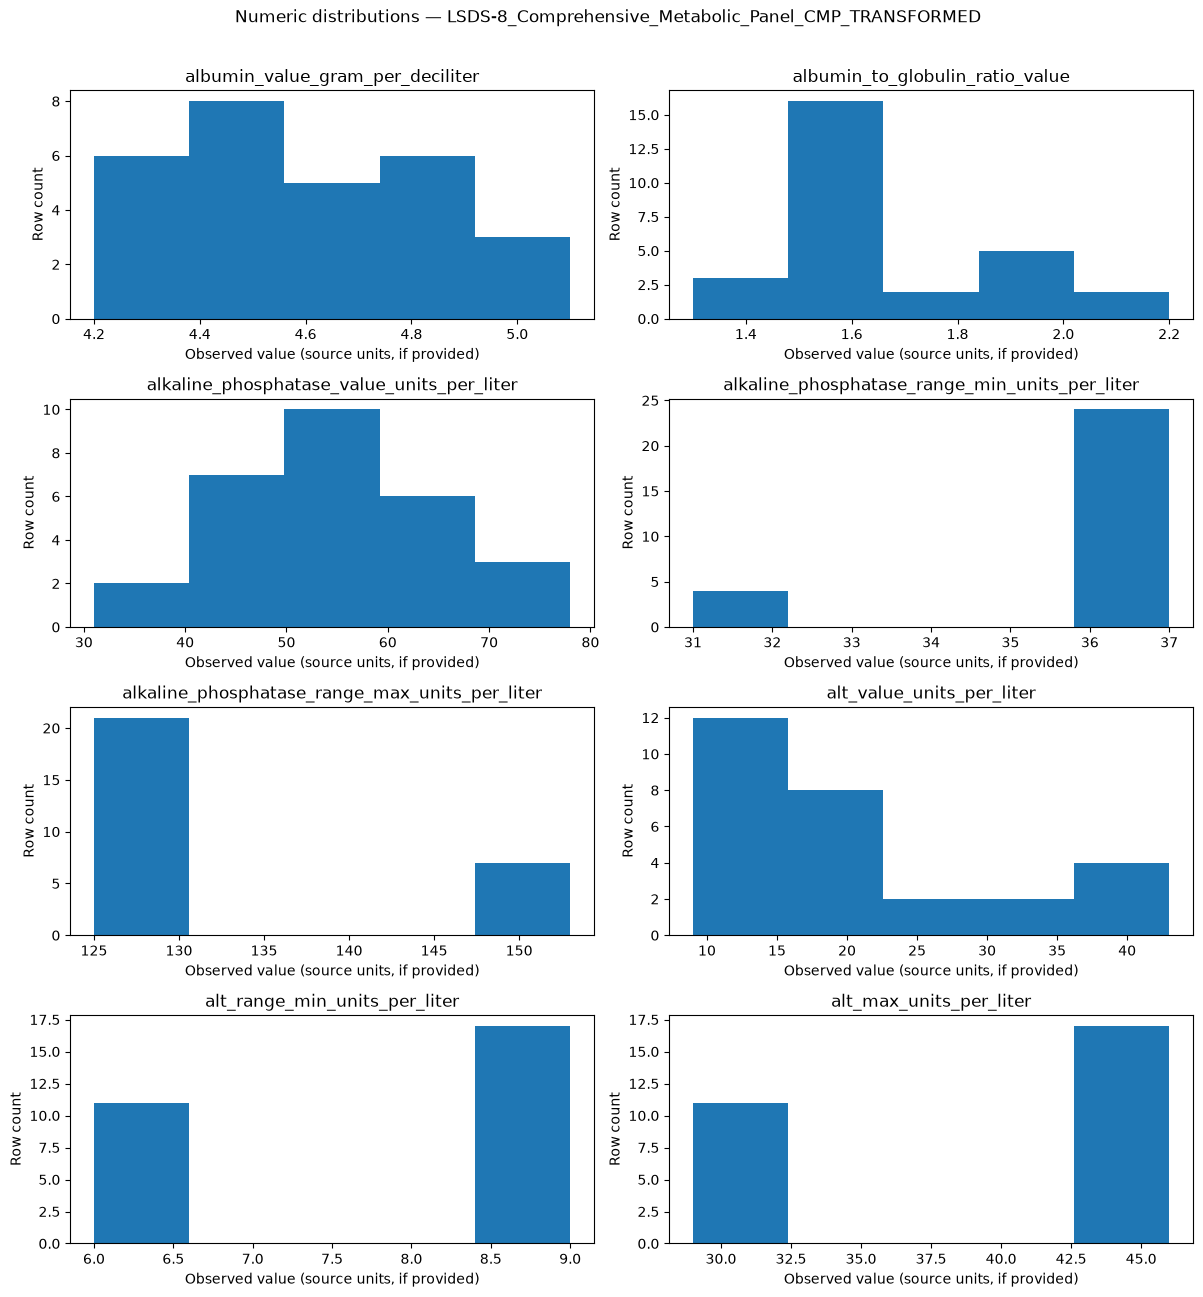

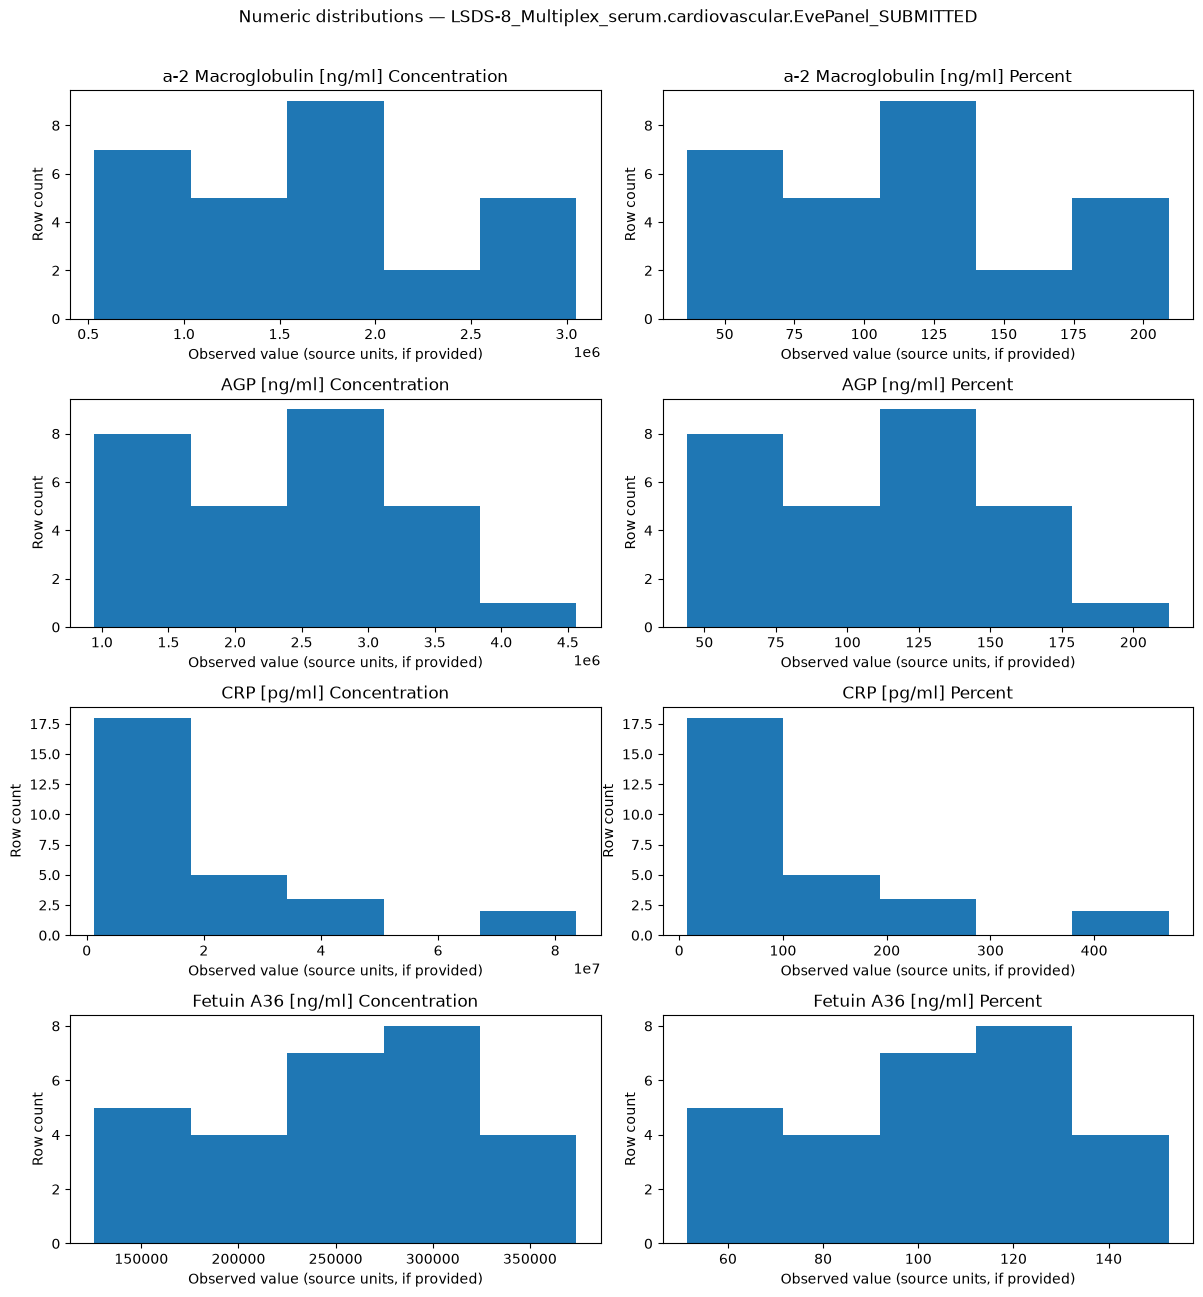

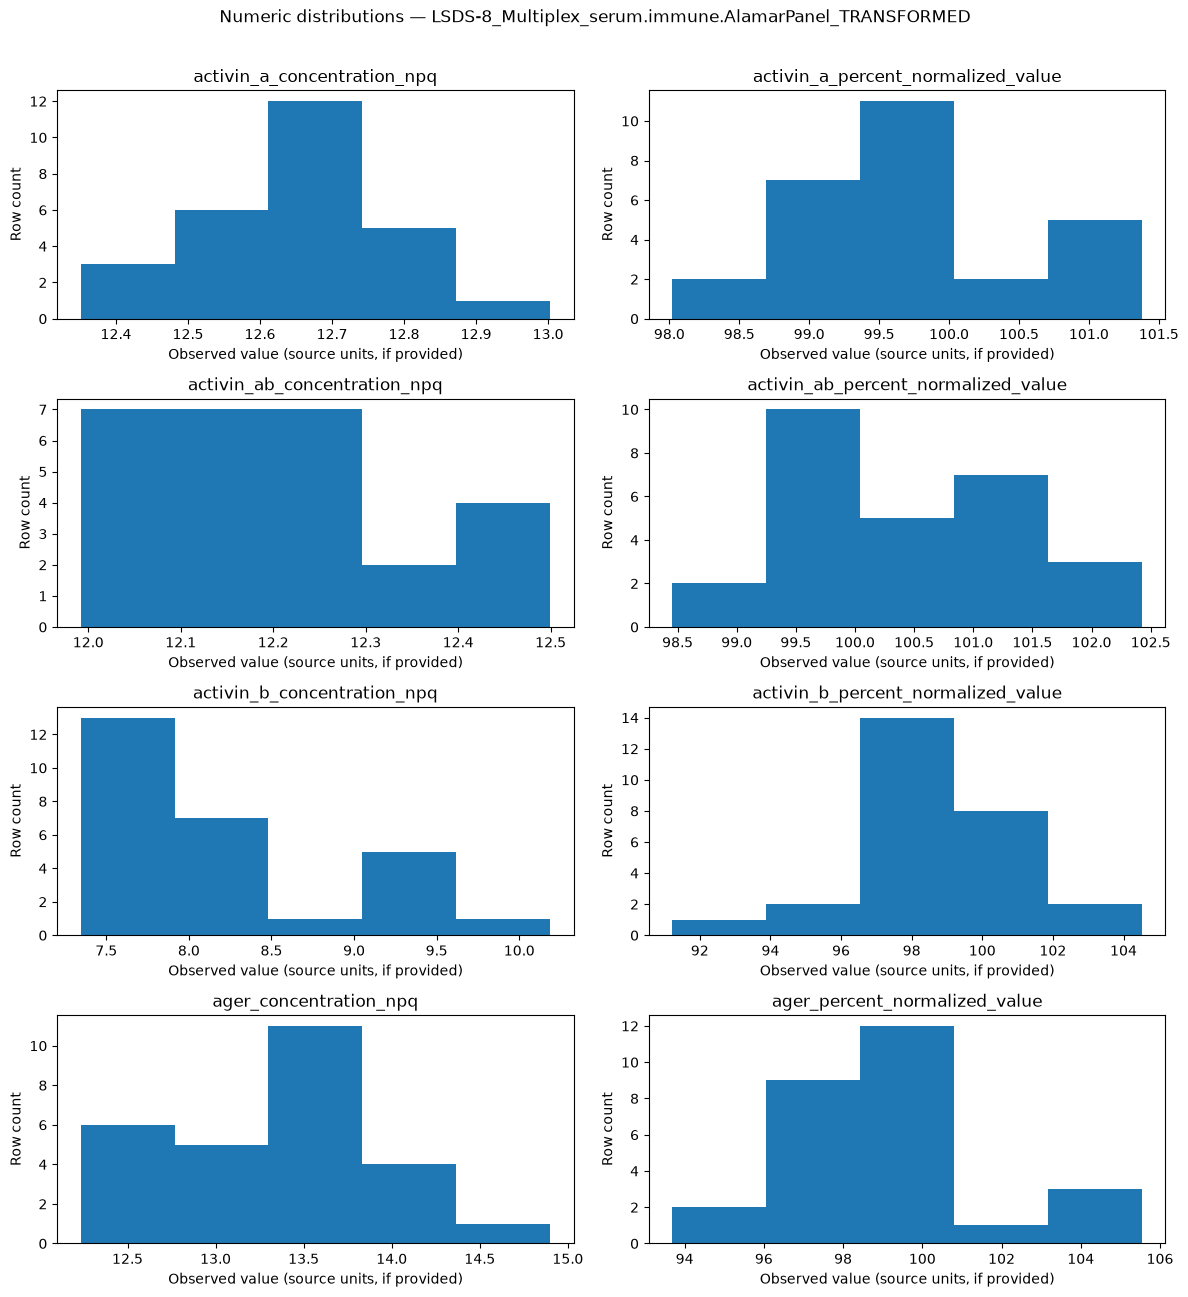

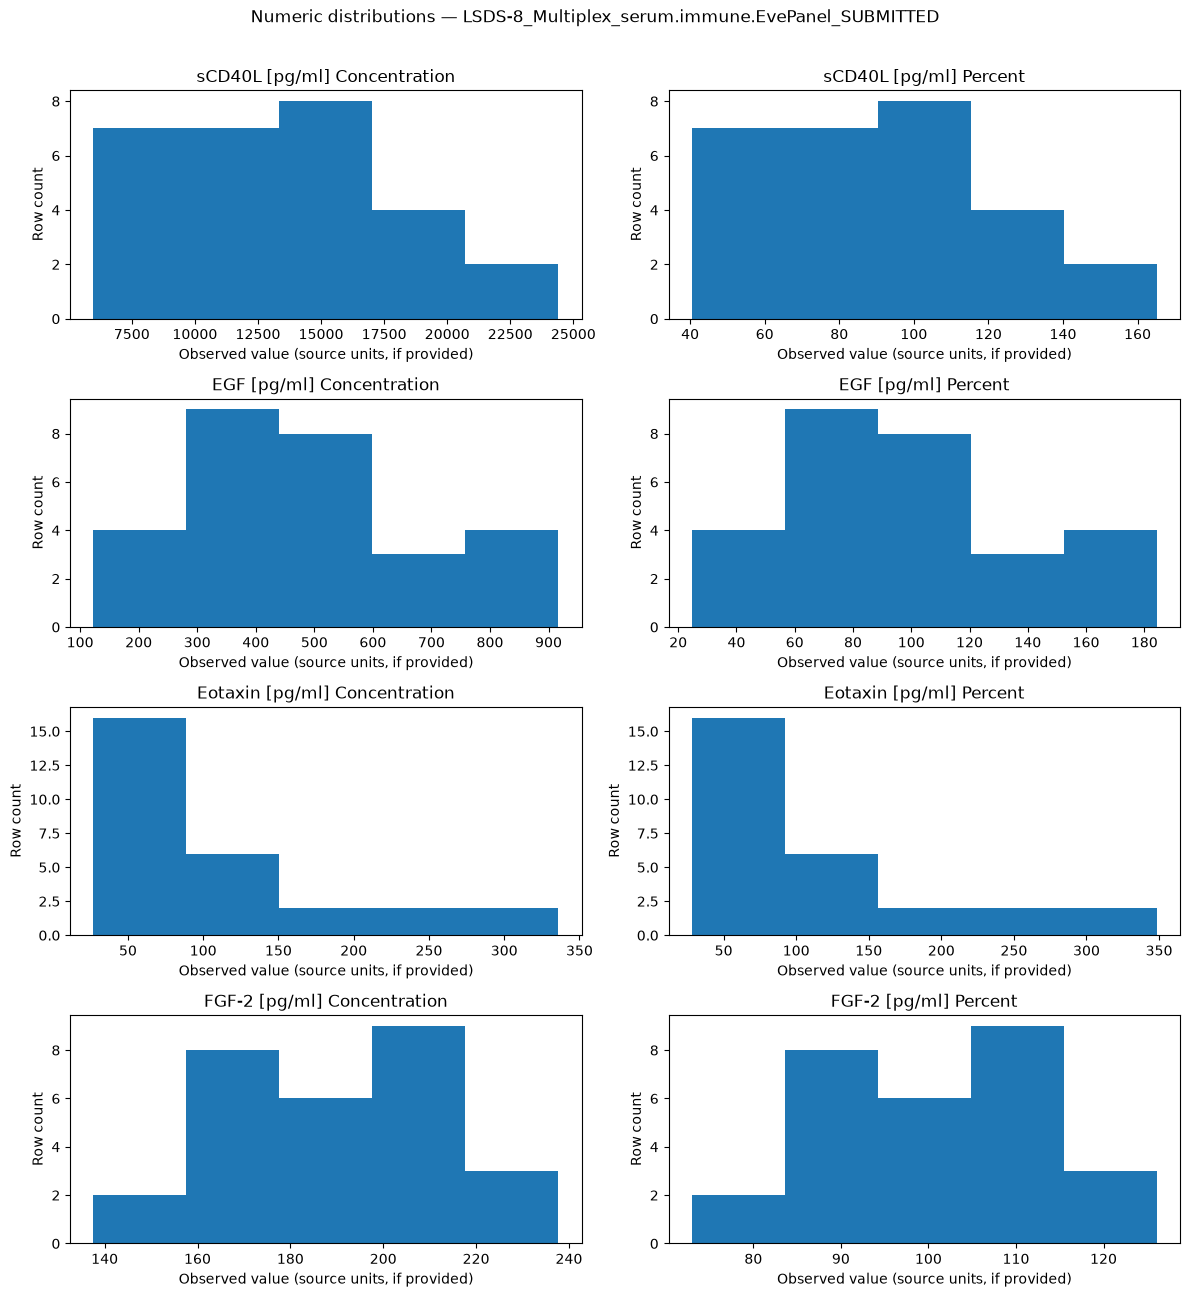

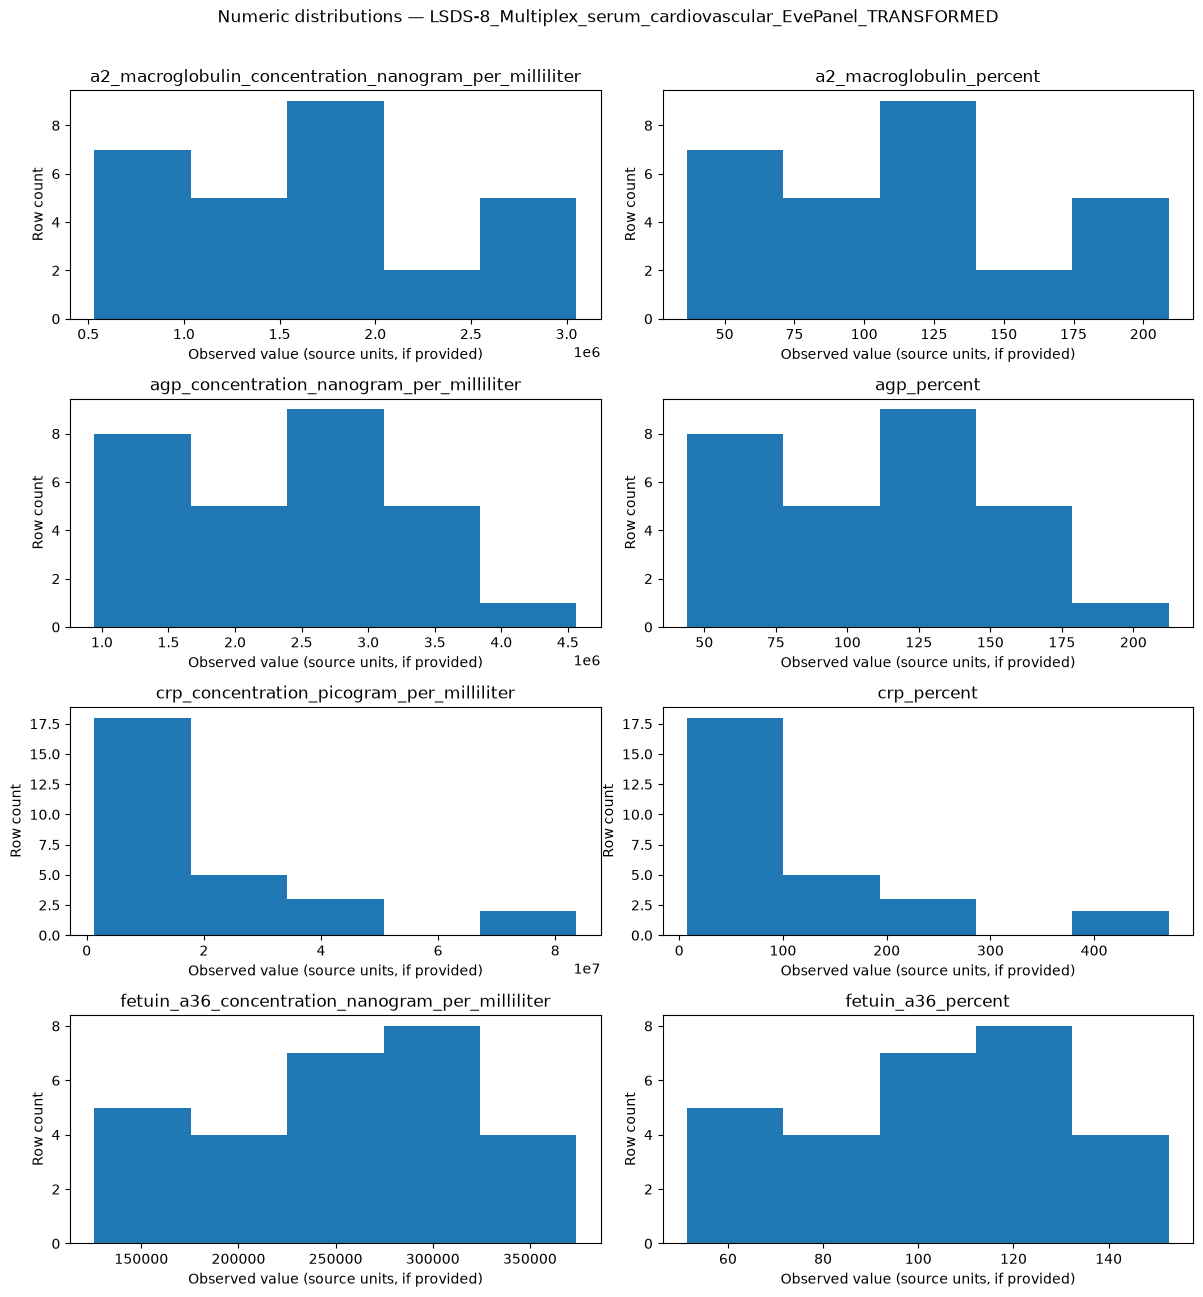

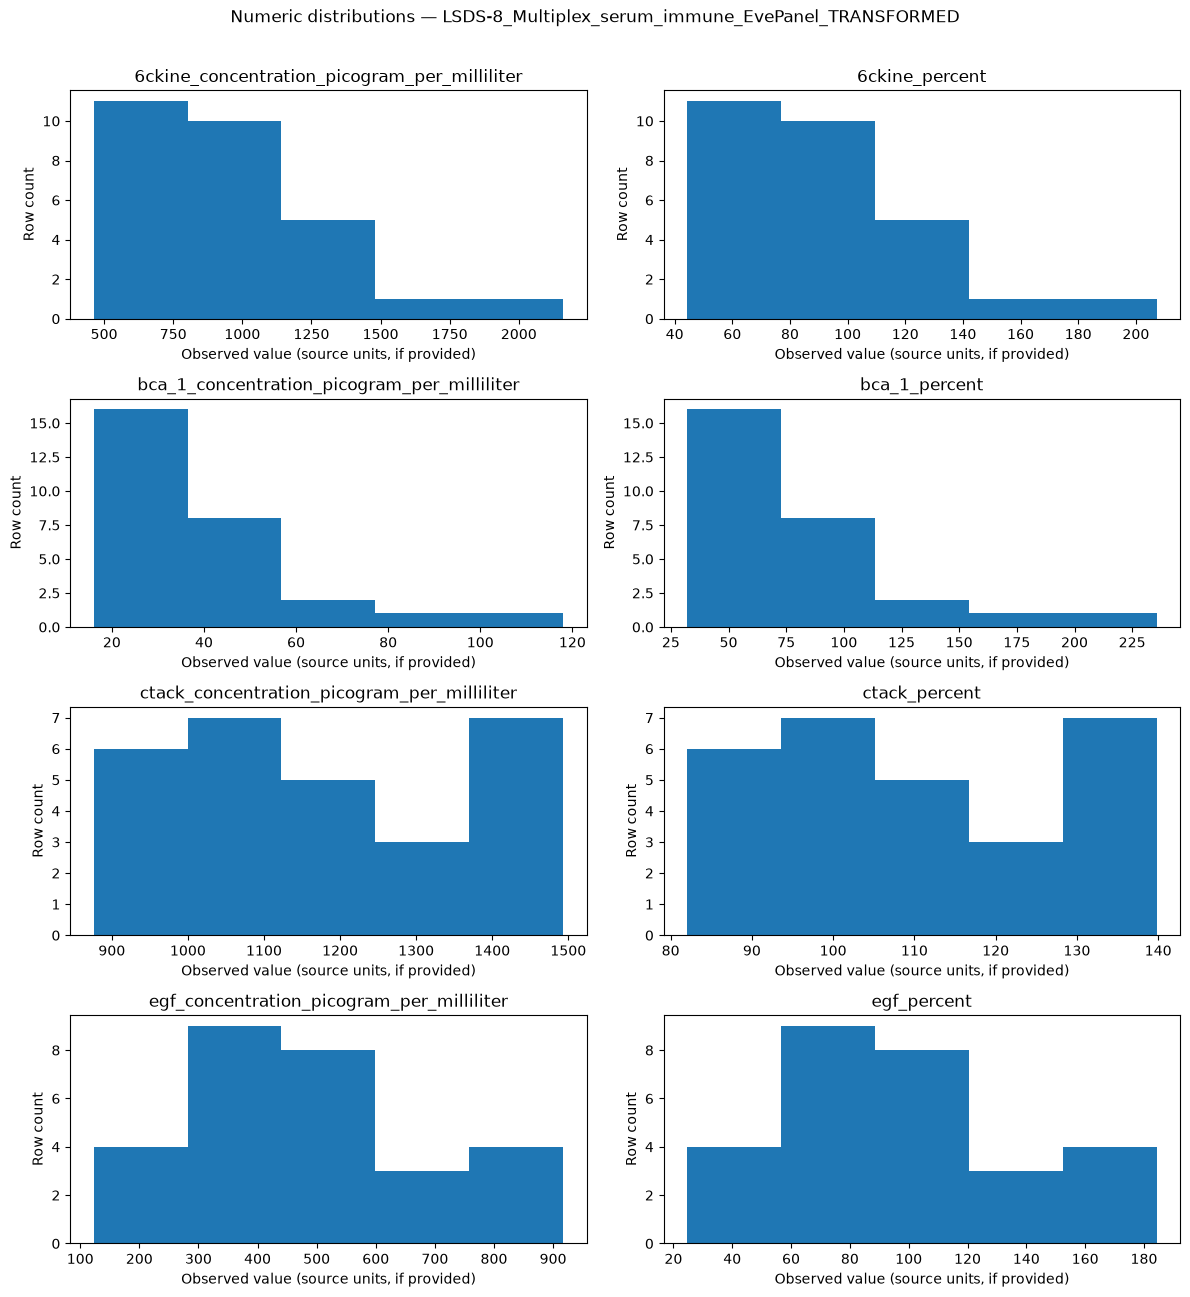

Distribution figures created: 7


In [10]:
# CELL 10 — plot numeric distributions without mixing different analytes/units
# Long-format multiplex results are plotted separately per analyte (and unit).
MAX_DISTRIBUTION_PLOTS_PER_TABLE = 8
plot_index = 0

for name, frame in assay_tables.items():
    analyte_cols = [c for c in frame.columns if ANALYTE_RE.search(str(c))]
    unit_cols = [c for c in frame.columns if UNIT_RE.search(str(c))]
    analyte_col = analyte_cols[0] if len(analyte_cols) == 1 else None
    unit_col = unit_cols[0] if len(unit_cols) == 1 else None

    numeric_cols = []
    for col in frame.columns:
        numeric = pd.to_numeric(frame[col], errors="coerce")
        nonmissing = int(frame[col].notna().sum())
        if nonmissing and numeric.notna().sum() / nonmissing >= 0.80 and numeric.nunique(dropna=True) > 1:
            numeric_cols.append(col)

    if not numeric_cols:
        print(f"No numeric measurement columns identified for {name}")
        continue

    plot_specs = []
    if analyte_col is not None:
        group_cols = [analyte_col]
        if unit_col is not None and unit_col != analyte_col:
            group_cols.append(unit_col)
        for group_key, group in frame.groupby(group_cols, dropna=False, sort=False):
            if not isinstance(group_key, tuple):
                group_key = (group_key,)
            analyte_label = str(group_key[0])
            unit_label = str(group_key[1]) if len(group_key) > 1 else ""
            for col in numeric_cols:
                values = pd.to_numeric(group[col], errors="coerce")
                values = values[np.isfinite(values)]
                if values.size > 1:
                    plot_specs.append((f"{analyte_label} [{unit_label}] {col}".strip(), values))
    else:
        for col in numeric_cols:
            values = pd.to_numeric(frame[col], errors="coerce")
            values = values[np.isfinite(values)]
            if values.size > 1:
                plot_specs.append((str(col), values))

    plot_specs = plot_specs[:MAX_DISTRIBUTION_PLOTS_PER_TABLE]
    if not plot_specs:
        print(f"No usable numeric distributions for {name}")
        continue

    ncols = 2
    nrows = int(np.ceil(len(plot_specs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, (label, values) in zip(axes, plot_specs):
        ax.hist(values, bins=min(15, max(5, int(np.sqrt(max(len(values), 1))))))
        ax.set_title(label[:70])
        ax.set_xlabel("Observed value (source units, if provided)")
        ax.set_ylabel("Row count")

    for ax in axes[len(plot_specs):]:
        ax.set_visible(False)

    fig.suptitle(f"Numeric distributions — {name}", y=1.01)
    fig.tight_layout()
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", name)[:100]
    fig.savefig(FIGURES_DIR / f"osd575_distributions_{safe_name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    plot_index += 1

print("Distribution figures created:", plot_index)


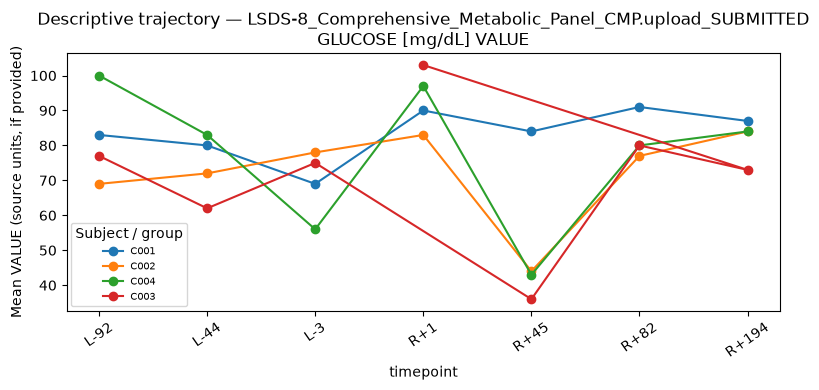

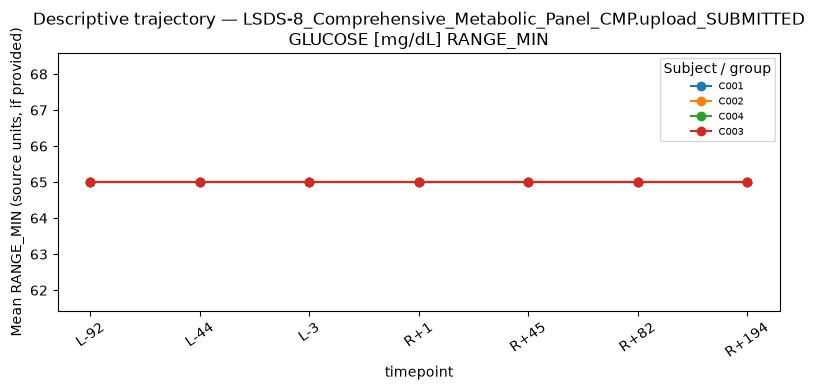

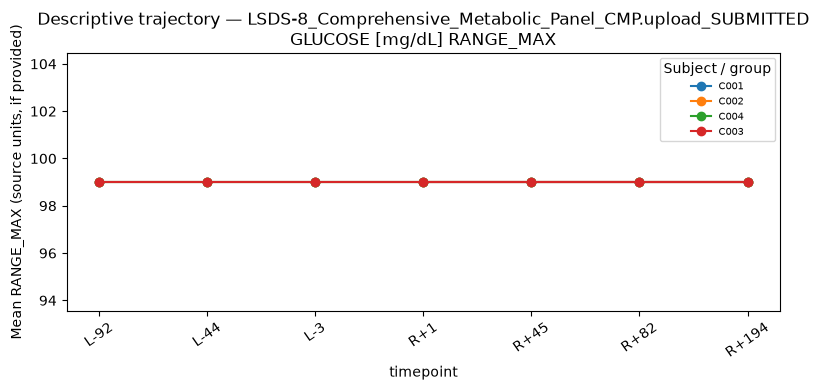

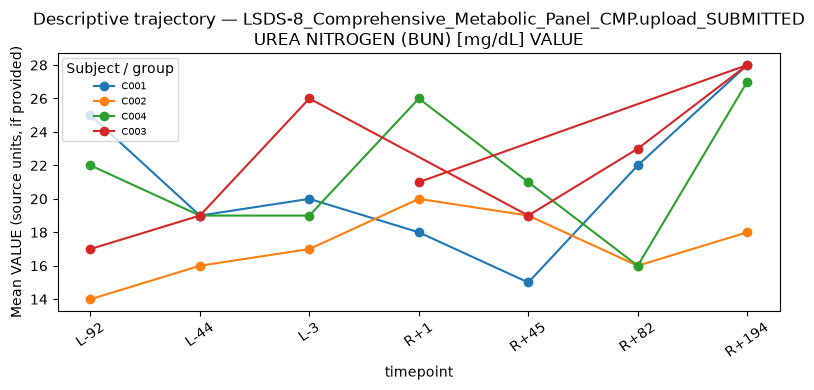

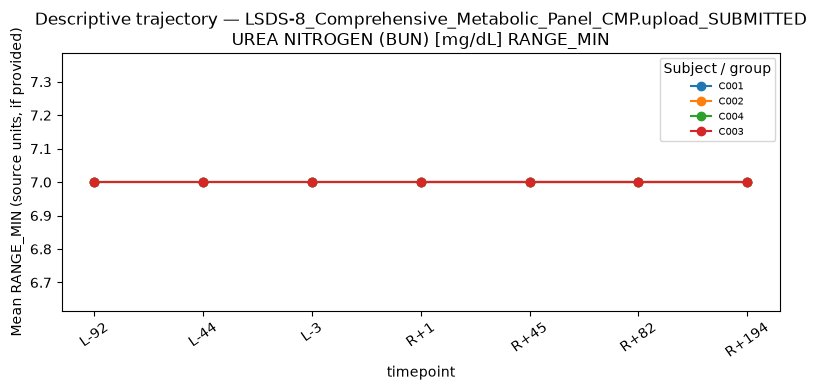

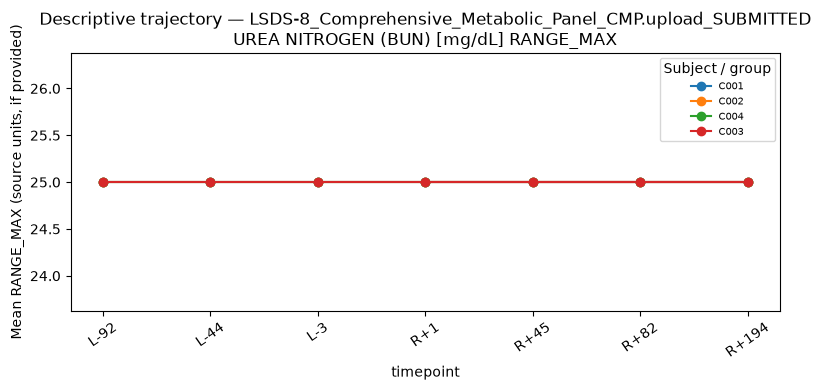

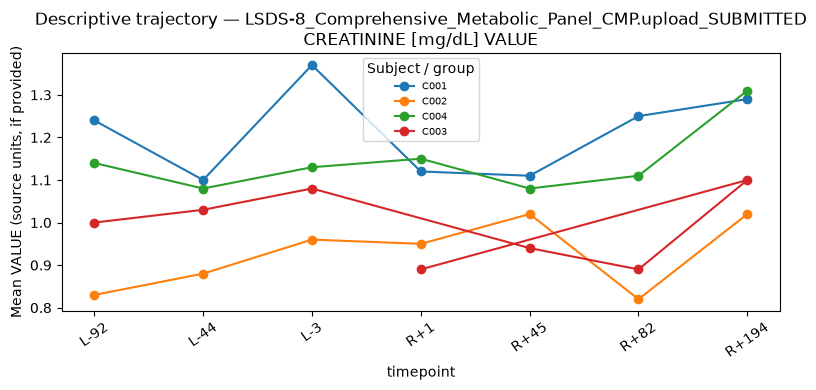

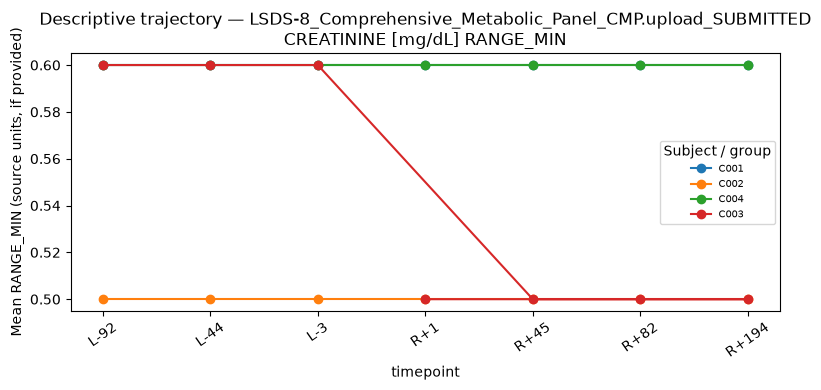

Skipping automatic trajectory plots for LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED: found 0 candidate time columns.
Skipping automatic trajectory plots for LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED: found 2 candidate time columns.
Skipping automatic trajectory plots for LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED: found 0 candidate time columns.
Skipping automatic trajectory plots for LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED: found 2 candidate time columns.
Skipping automatic trajectory plots for LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED: found 0 candidate time columns.
Skipping automatic trajectory plots for LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED: found 0 candidate time columns.


,table,time_column,subject_column,measurement,n_subject_groups,n_timepoints,timepoints_in_source_order
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,GLUCOSE [mg/dL] VALUE,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,GLUCOSE [mg/dL] RANGE_MIN,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,GLUCOSE [mg/dL] RANGE_MAX,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
3,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,UREA NITROGEN (BUN) [mg/dL] VALUE,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
4,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,UREA NITROGEN (BUN) [mg/dL] RANGE_MIN,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,UREA NITROGEN (BUN) [mg/dL] RANGE_MAX,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,CREATININE [mg/dL] VALUE,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194
7,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,timepoint,SUBJECT_ID,CREATININE [mg/dL] RANGE_MIN,4,7,L-92 | L-44 | L-3 | R+1 | R+45 | R+82 | R+194


If this inventory is empty, the files did not expose an unambiguous timepoint + numeric measurement structure.


In [11]:
# CELL 11 — explore longitudinal patterns without pooling subjects or analytes
# When subject/analyte identifiers exist, keep their trajectories separate.
SUBJECT_RE = re.compile(r"(subject|participant|crew|astronaut).*(id|identifier)?$|^(subject|participant|crew|astronaut)$", re.I)
trajectory_rows = []
MAX_TRAJECTORY_PLOTS_PER_TABLE = 8

for name, frame in assay_tables.items():
    possible_time_cols = [c for c in frame.columns if TIME_RE.search(str(c))]
    if len(possible_time_cols) != 1:
        print(f"Skipping automatic trajectory plots for {name}: found {len(possible_time_cols)} candidate time columns.")
        continue
    time_col = possible_time_cols[0]

    subject_cols = [c for c in frame.columns if SUBJECT_RE.search(str(c))]
    subject_col = subject_cols[0] if len(subject_cols) == 1 else None
    analyte_cols = [c for c in frame.columns if ANALYTE_RE.search(str(c))]
    analyte_col = analyte_cols[0] if len(analyte_cols) == 1 else None
    unit_cols = [c for c in frame.columns if UNIT_RE.search(str(c))]
    unit_col = unit_cols[0] if len(unit_cols) == 1 else None

    numeric_cols = []
    for col in frame.columns:
        if col == time_col or col == subject_col or col == analyte_col or col == unit_col:
            continue
        if IDENTIFIER_RE.search(str(col)):
            continue
        numeric = pd.to_numeric(frame[col], errors="coerce")
        nonmissing = int(frame[col].notna().sum())
        if nonmissing and numeric.notna().sum() / nonmissing >= 0.80:
            numeric_cols.append(col)

    if not numeric_cols:
        continue

    plot_specs = []
    if analyte_col is not None:
        analyte_values = frame[analyte_col].dropna().astype(str).unique().tolist()
        for analyte_value in analyte_values:
            selected = frame.loc[frame[analyte_col].astype(str) == analyte_value]
            unit_values = selected[unit_col].dropna().astype(str).unique().tolist() if unit_col is not None else [""]
            for unit_value in unit_values:
                unit_selected = selected if unit_col is None else selected.loc[selected[unit_col].astype(str) == unit_value]
                for col in numeric_cols:
                    plot_specs.append((f"{analyte_value} [{unit_value}] {col}".strip(), unit_selected, col))
    else:
        for col in numeric_cols:
            plot_specs.append((str(col), frame, col))

    for label, subset, value_col in plot_specs[:MAX_TRAJECTORY_PLOTS_PER_TABLE]:
        time_values = subset[time_col].astype("string").str.strip()
        value_values = pd.to_numeric(subset[value_col], errors="coerce")
        tmp = pd.DataFrame({"timepoint": time_values, "value": value_values})
        if subject_col is not None:
            tmp["subject"] = subset[subject_col].astype("string").values
        else:
            tmp["subject"] = "All available rows (subject field not detected)"
        tmp = tmp.dropna(subset=["timepoint", "value"])
        if tmp.empty or tmp["timepoint"].nunique() < 2:
            continue

        # Retain the source order; do not invent missing visits.
        ordered_timepoints = list(pd.unique(tmp["timepoint"]))
        tmp["timepoint"] = pd.Categorical(tmp["timepoint"], categories=ordered_timepoints, ordered=True)
        grouped = tmp.groupby(["subject", "timepoint"], observed=False, sort=False)["value"].agg(["count", "mean", "std", "median"]).reset_index()
        grouped["timepoint"] = grouped["timepoint"].astype(str)
        trajectory_rows.append({
            "table": name,
            "time_column": str(time_col),
            "subject_column": str(subject_col) if subject_col is not None else "not detected",
            "measurement": label,
            "n_subject_groups": int(grouped["subject"].nunique()),
            "n_timepoints": int(grouped["timepoint"].nunique()),
            "timepoints_in_source_order": " | ".join(ordered_timepoints),
        })

        fig, ax = plt.subplots(figsize=(8, 4))
        for subject_name, subject_frame in grouped.groupby("subject", sort=False):
            ax.plot(subject_frame["timepoint"], subject_frame["mean"], marker="o", label=str(subject_name))
        ax.set_title(f"Descriptive trajectory — {name}\n{label}")
        ax.set_xlabel(str(time_col))
        ax.set_ylabel(f"Mean {value_col} (source units, if provided)")
        ax.tick_params(axis="x", rotation=35)
        if grouped["subject"].nunique() <= 8:
            ax.legend(fontsize=7, title="Subject / group")
        fig.tight_layout()
        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", f"{name}_{label}")[:110]
        fig.savefig(FIGURES_DIR / f"osd575_timecourse_{safe_name}.png", dpi=140, bbox_inches="tight")
        plt.show()
        plt.close(fig)

trajectory_df = pd.DataFrame(trajectory_rows)
display(trajectory_df)
trajectory_df.to_csv(TABLES_DIR / "osd575_timecourse_plot_inventory.csv", index=False)
print("If this inventory is empty, the files did not expose an unambiguous timepoint + numeric measurement structure.")


In [12]:
# CELL 12 — compare SUBMITTED and TRANSFORMED file pairs without merging them
# The comparison is structural: row/column counts, common columns, and numeric-column summaries.
pair_rows = []
family_groups = provenance_df.groupby("assay_family")

for family, group in family_groups:
    submitted_names = group.loc[group["file_version"] == "SUBMITTED", "table"].tolist()
    transformed_names = group.loc[group["file_version"] == "TRANSFORMED", "table"].tolist()
    for sub_name in submitted_names:
        for trans_name in transformed_names:
            sub = assay_tables[sub_name]
            trans = assay_tables[trans_name]
            sub_cols = set(map(str, sub.columns))
            trans_cols = set(map(str, trans.columns))
            common = sorted(sub_cols & trans_cols)
            pair_rows.append({
                "assay_family": family,
                "submitted_table": sub_name,
                "transformed_table": trans_name,
                "submitted_shape": str(sub.shape),
                "transformed_shape": str(trans.shape),
                "common_column_count": len(common),
                "submitted_only_columns": " | ".join(sorted(sub_cols - trans_cols)),
                "transformed_only_columns": " | ".join(sorted(trans_cols - sub_cols)),
                "common_columns": " | ".join(common),
            })

pair_comparison = pd.DataFrame(pair_rows)
display(pair_comparison)
pair_comparison.to_csv(TABLES_DIR / "osd575_submitted_transformed_structural_comparison.csv", index=False)


,assay_family,submitted_table,transformed_table,submitted_shape,transformed_shape,common_column_count,submitted_only_columns,transformed_only_columns,common_columns
0,cardiovascular_multiplex,LSDS-8_Multiplex_serum.cardiovascular.EvePanel...,LSDS-8_Multiplex_serum_cardiovascular_EvePanel...,"(252, 8)","(28, 19)",0,Analyte | Concentration | ID | Percent | Timep...,Sample Name | a2_macroglobulin_concentration_n...,
1,comprehensive_metabolic_panel,LSDS-8_Comprehensive_Metabolic_Panel_CMP.uploa...,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,"(531, 9)","(28, 58)",0,ANALYTE | RANGE_MAX | RANGE_MIN | SEX | SUBJEC...,Sample Name | albumin_range_max_gram_per_decil...,
2,immune_eve_multiplex,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,"(1988, 8)","(28, 143)",0,Analyte | Concentration | ID | Percent | Timep...,6ckine_concentration_picogram_per_milliliter |...,


Skipping correlation matrix for long-format analyte table: LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED


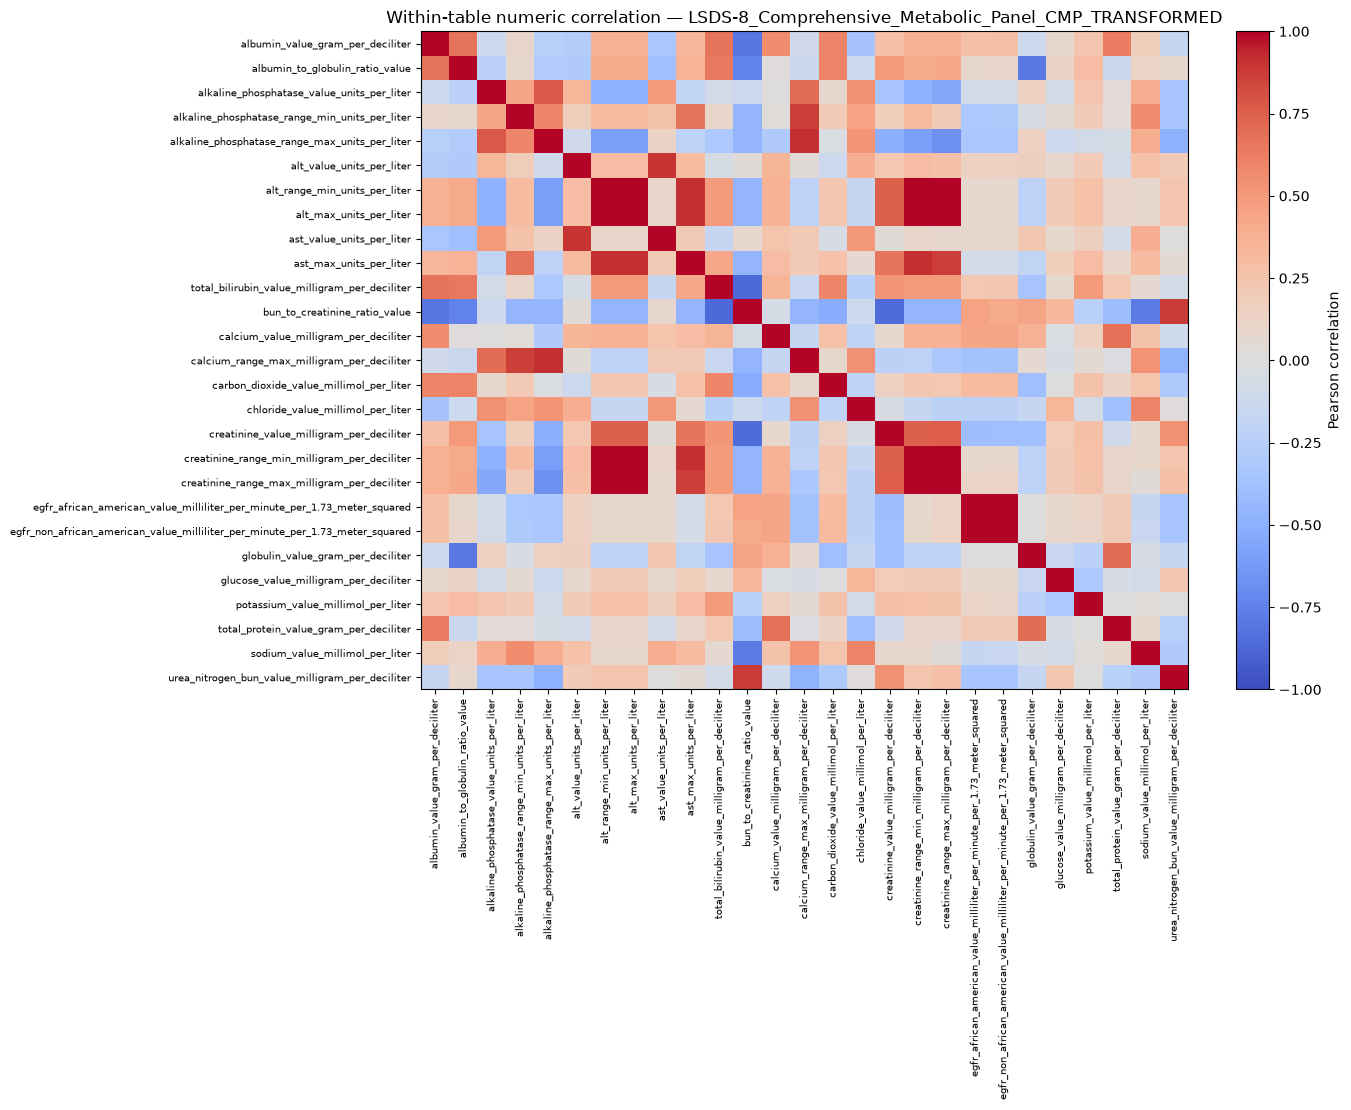

Skipping correlation matrix for long-format analyte table: LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED


C:\Users\Ankit Bhadra\AppData\Local\Temp\ipykernel_29488\3050028819.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  numeric_data[str(col)] = numeric


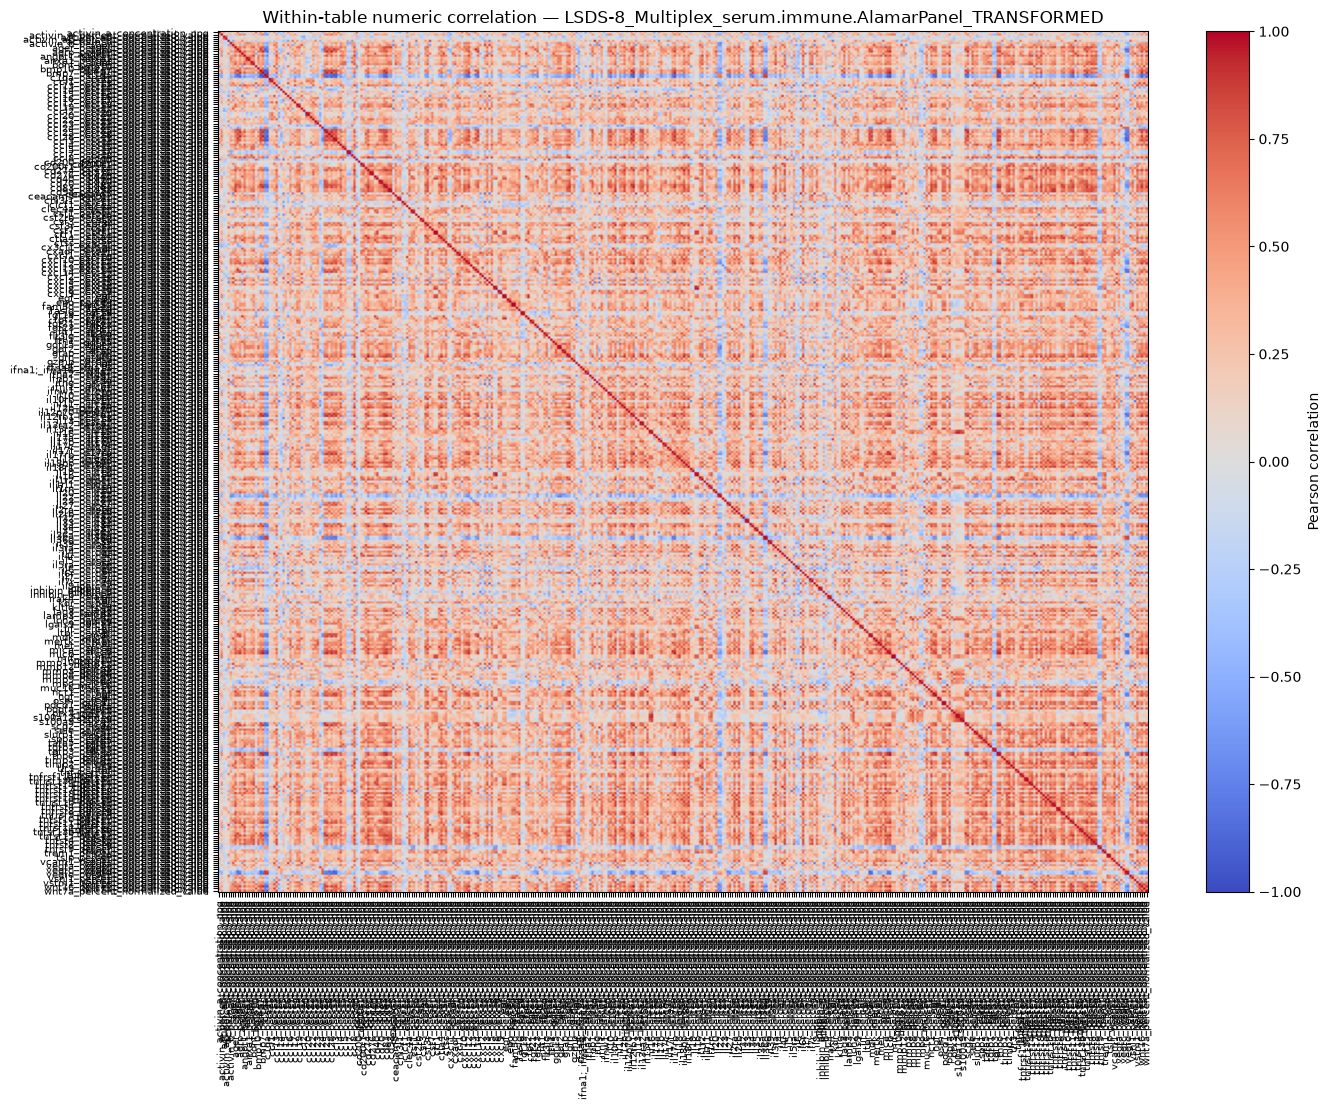

Skipping correlation matrix for long-format analyte table: LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED


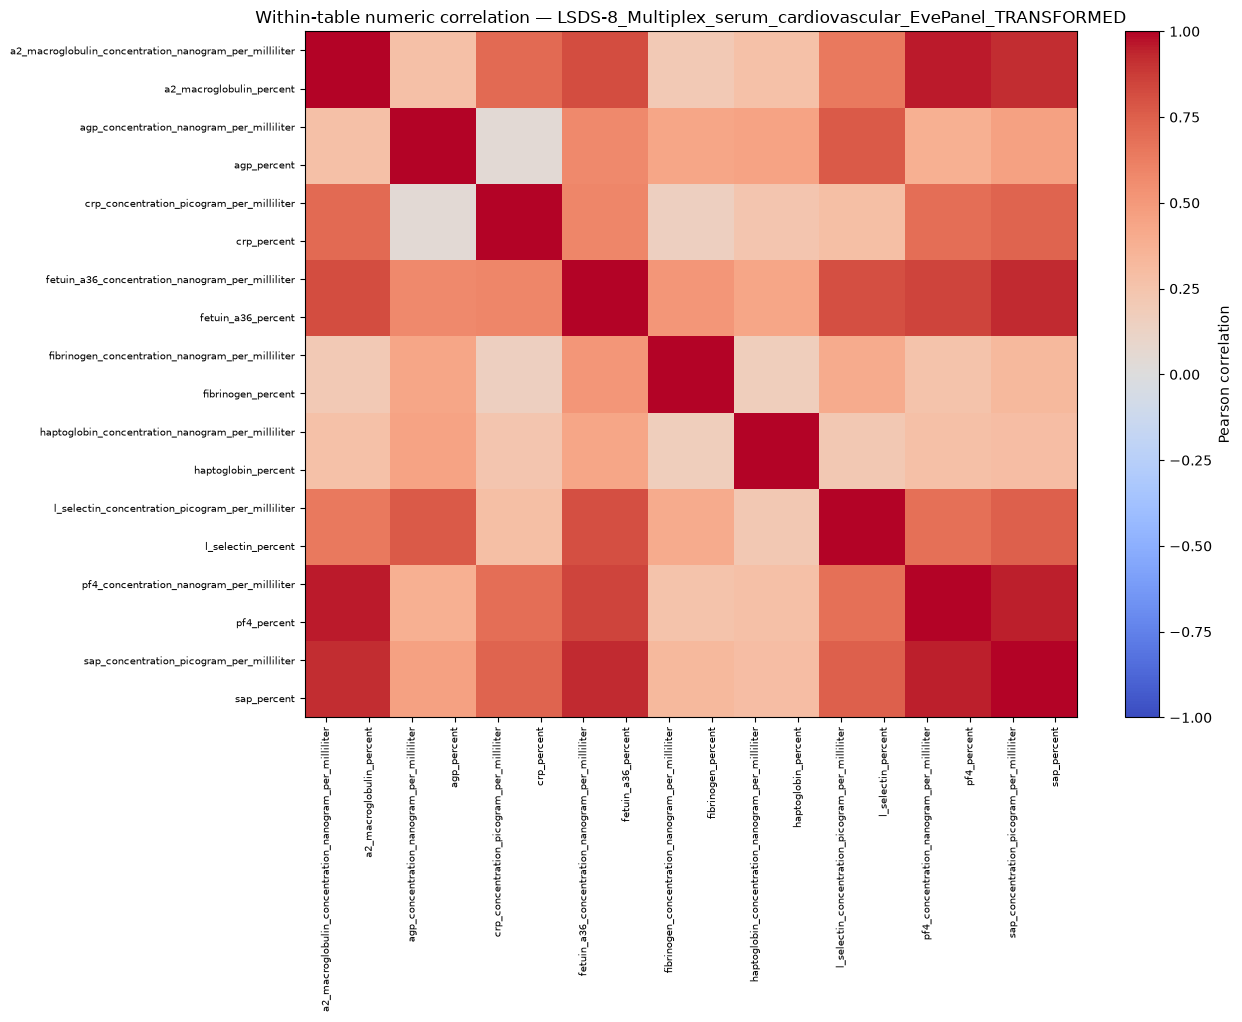

C:\Users\Ankit Bhadra\AppData\Local\Temp\ipykernel_29488\3050028819.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  numeric_data[str(col)] = numeric


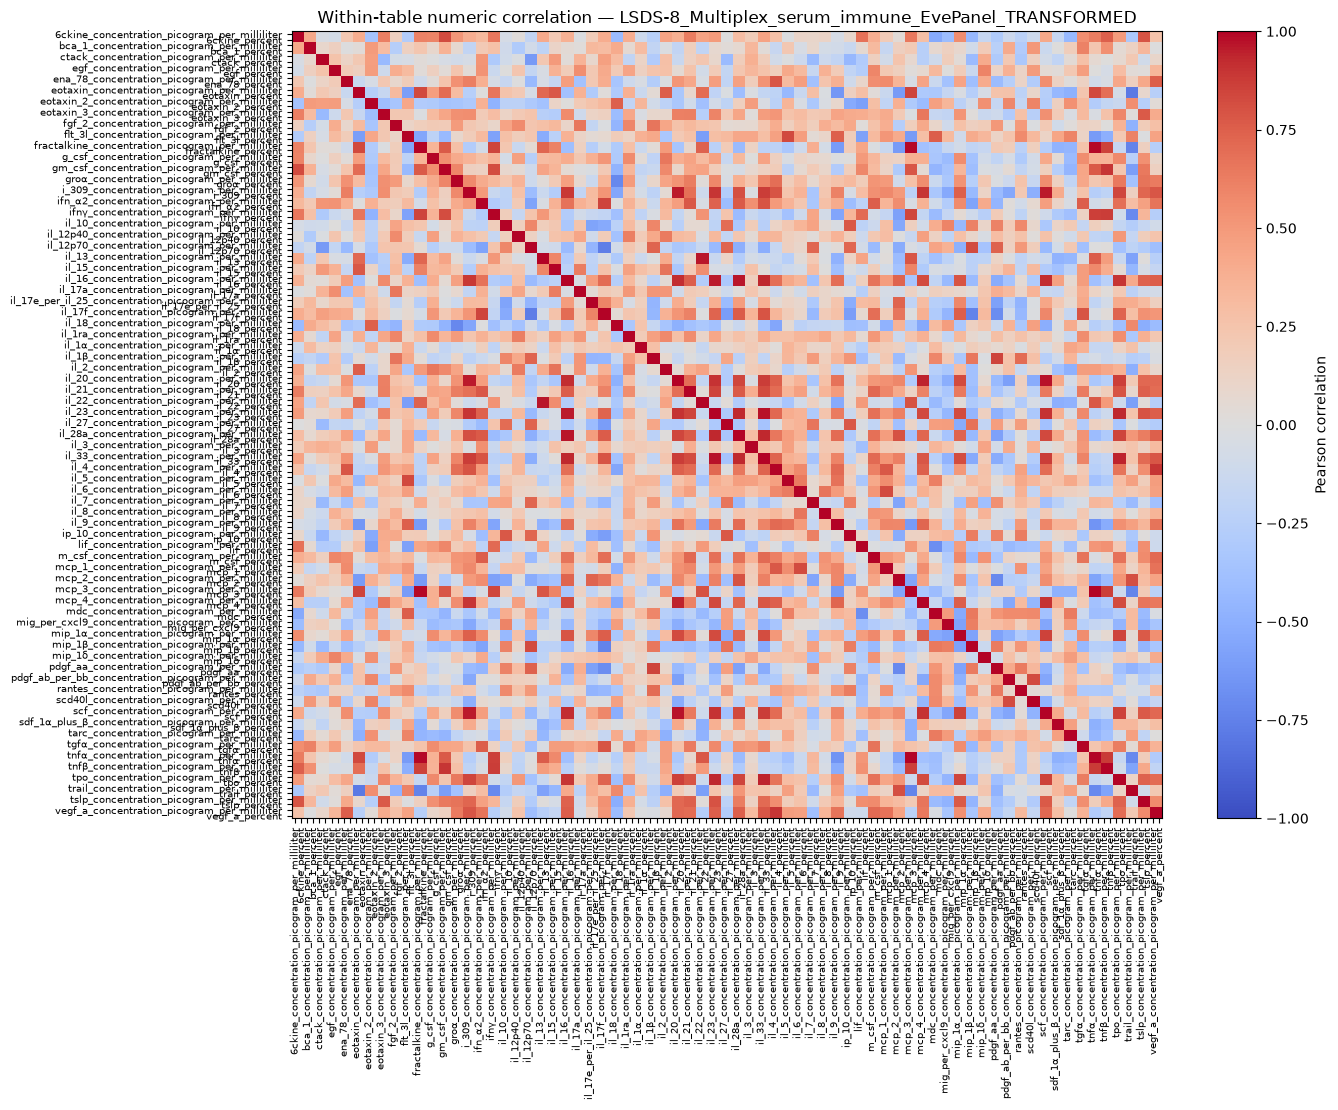

,table,numeric_columns,n_rows
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANS...,27,28
1,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRAN...,406,27
2,LSDS-8_Multiplex_serum_cardiovascular_EvePanel...,18,28
3,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFO...,142,28


In [13]:
# CELL 13 — correlation matrices within each table (numeric columns only)
# Correlations are descriptive and are never computed across assay families or units.
correlation_inventory = []

for name, frame in assay_tables.items():
    # A long-format assay may store multiple analytes in one repeated Result column.
    # Skip correlation across such rows because analytes/units are not interchangeable.
    if sum(1 for c in frame.columns if ANALYTE_RE.search(str(c))) == 1:
        print(f"Skipping correlation matrix for long-format analyte table: {name}")
        continue
    numeric_data = pd.DataFrame(index=frame.index)
    for col in frame.columns:
        numeric = pd.to_numeric(frame[col], errors="coerce")
        nonmissing = int(frame[col].notna().sum())
        if nonmissing and numeric.notna().sum() / nonmissing >= 0.80 and numeric.nunique(dropna=True) > 1:
            numeric_data[str(col)] = numeric

    if numeric_data.shape[1] < 2:
        continue

    corr = numeric_data.corr(min_periods=3)
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", name)[:100]
    corr.to_csv(TABLES_DIR / f"osd575_correlation_{safe_name}.csv")

    fig_w = max(7, min(14, 0.55 * len(corr.columns) + 3))
    fig, ax = plt.subplots(figsize=(fig_w, fig_w * 0.8))
    image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
    ax.set_yticklabels(corr.index, fontsize=7)
    ax.set_title(f"Within-table numeric correlation — {name}")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"osd575_correlation_{safe_name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    correlation_inventory.append({"table": name, "numeric_columns": numeric_data.shape[1], "n_rows": len(frame)})

correlation_inventory_df = pd.DataFrame(correlation_inventory)
display(correlation_inventory_df)


In [14]:
# CELL 14 — generate a concise EDA report

def md_table(frame, max_rows=30):
    if frame is None or frame.empty:
        return "_No records available._"
    view = frame.head(max_rows).fillna("")
    headers = [str(c) for c in view.columns]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for _, row in view.iterrows():
        vals = [str(v).replace("|", "/").replace("\n", " ") for v in row.tolist()]
        lines.append("| " + " | ".join(vals) + " |")
    return "\n".join(lines)

report_lines = [
    "# NASA OSD-575 Biomarker EDA Report",
    "",
    f"- Workstream: `{WORKSTREAM_ROOT}`",
    f"- Raw folder: `{RAW_DIR}`",
    f"- Files discovered: {len(all_files)}",
    f"- Assay tables loaded: {len(assay_tables)}",
    f"- Report generated: {pd.Timestamp.now().isoformat(timespec='seconds')}",
    "",
    "## Important interpretation limits",
    "- OSD-575 concerns four Inspiration4 crew members; repeated samples do not turn this into a large independent cohort.",
    "- The plots and summaries are descriptive, not clinical interpretation or population-level inference.",
    "- SUBMITTED and TRANSFORMED files are profiled separately. This notebook does not choose a canonical source or merge these versions.",
    "- Numerical values are not compared across assays unless their units and analyte definitions are confirmed.",
    "- Any timepoint shown is taken from the actual file values; the study-page schedule is not imposed on the data.",
    "",
    "## Assay table inventory",
    md_table(provenance_df.sort_values(["assay_family", "file_version", "table"])),
    "",
    "## Load status",
    md_table(load_log_df),
    "",
    "## Structural comparison of submitted and transformed files",
    md_table(pair_comparison),
    "",
    "## Numeric measurements detected",
    md_table(measurement_summary, max_rows=100),
    "",
    "## Subject and timepoint candidates",
    md_table(category_candidates, max_rows=100),
    "",
    "## Generated files",
    "- `reports/tables/osd575_eda_file_inventory.csv`",
    "- `reports/tables/osd575_eda_load_log.csv`",
    "- `reports/tables/osd575_eda_table_schema.csv`",
    "- `reports/tables/osd575_assay_provenance.csv`",
    "- `reports/tables/osd575_column_role_candidates.csv`",
    "- `reports/tables/osd575_numeric_measurement_summary.csv`",
    "- `reports/tables/osd575_column_missingness.csv`",
    "- `reports/tables/osd575_subject_timepoint_candidates.csv`",
    "- `reports/tables/osd575_submitted_transformed_structural_comparison.csv`",
    "- `reports/tables/osd575_timecourse_plot_inventory.csv`",
    "- Figures are saved under `reports/figures/`.",
    "",
    "## Source",
    "NASA OSDR, OSD-575: https://osdr.nasa.gov/bio/repo/data/studies/OSD-575",
    "Study DOI: https://doi.org/10.26030/mc5d-p710",
]

report_path = REPORTS_DIR / "osd575_biomarker_eda_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("EDA report saved:", report_path)
print("Tables saved:", TABLES_DIR)
print("Figures saved:", FIGURES_DIR)


EDA report saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\osd575_biomarker_eda_report.md
Tables saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\tables
Figures saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\figures


C:\Users\Ankit Bhadra\AppData\Local\Temp\ipykernel_29488\3704078741.py:6: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  view = frame.head(max_rows).fillna("")
C:\Users\Ankit Bhadra\AppData\Local\Temp\ipykernel_29488\3704078741.py:6: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  view = frame.head(max_rows).fillna("")
